In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import StratifiedKFold
import matplotlib.pyplot as plt


In [ ]:

from google.colab import files

uploaded = files.upload()

nama_file = next(iter(uploaded))

if nama_file.endswith((".xlsx", ".xls")):
    df = pd.read_excel(nama_file)
elif nama_file.endswith(".csv"):
    df = pd.read_csv(nama_file)
else:
    raise ValueError("Format file harus Excel atau CSV.")

print("Dataset berhasil dimuat!")
print("Nama file:", nama_file)
print("Ukuran dataset:", df.shape)

display(df.head())


Saving DATA BENIH LELE 2026.xlsx to DATA BENIH LELE 2026 (1).xlsx
Dataset berhasil dimuat!
Nama file: DATA BENIH LELE 2026 (1).xlsx
Ukuran dataset: (2790, 7)


,Tanggal,Sesi,Waktu Aktual,Suhu (°C),pH,TDS,Kekeruhan
0,2026-09-15,07:00,2026-09-15 07:01:57.000,25.94,"6,75",728.69,145.21
1,2026-09-15,07:00,2026-09-15 07:02:28.000,25.94,"6,75",728.69,145.21
2,2026-09-15,07:00,2026-09-15 07:02:57.004,25.94,"6,75",688.40,142.87
3,2026-09-15,07:00,2026-09-15 07:03:27.198,25.94,"6,75",670.59,123.75
4,2026-09-15,07:00,2026-09-15 07:03:57.493,25.94,"6,75",650.11,103.29


# Data Understanding

In [ ]:
print("Jumlah baris:", df.shape[0])
print("Jumlah kolom:", df.shape[1])
print("Total data:", df.shape[0] * df.shape[1])

Jumlah baris: 2790
Jumlah kolom: 7
Total data: 19530


In [ ]:
df.shape

(2790, 7)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2790 entries, 0 to 2789
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Tanggal       2790 non-null   datetime64[ns]
 1   Sesi          2790 non-null   object        
 2   Waktu Aktual  2790 non-null   datetime64[ns]
 3   Suhu (°C)     2778 non-null   float64       
 4   pH            2775 non-null   object        
 5   TDS           2781 non-null   float64       
 6   Kekeruhan     2777 non-null   float64       
dtypes: datetime64[ns](2), float64(3), object(2)
memory usage: 152.7+ KB


In [ ]:
display(df.describe())

,Tanggal,Waktu Aktual,Suhu (°C),TDS,Kekeruhan
count,2790,2790,2778.00000,2781.000000,2777.000000
mean,2026-09-30 00:00:00,2026-09-30 12:12:00.607317760,29.17221,572.264117,223.889125
min,2026-09-15 00:00:00,2026-09-15 07:01:57,25.94000,0.000000,0.000000
25%,2026-09-22 00:00:00,2026-09-22 17:03:44.839249920,27.31000,359.120000,169.390000
50%,2026-09-30 00:00:00,2026-09-30 12:13:12.980999936,29.56000,524.230000,240.030000
75%,2026-10-08 00:00:00,2026-10-08 07:33:04.079500032,30.50000,711.850000,292.140000
max,2026-10-15 00:00:00,2026-10-15 17:15:12.681000,32.19000,2418.890000,343.980000
std,NaN,NaN,1.79527,307.701223,82.192689


In [ ]:
print("Nama kolom dataset:")
print(df.columns.tolist())

Nama kolom dataset:
['Tanggal', 'Sesi', 'Waktu Aktual', 'Suhu (°C)', 'pH', 'TDS', 'Kekeruhan']


array([[<Axes: title={'center': 'Suhu (°C)'}>,
        <Axes: title={'center': 'TDS'}>],
       [<Axes: title={'center': 'Kekeruhan'}>, <Axes: >]], dtype=object)

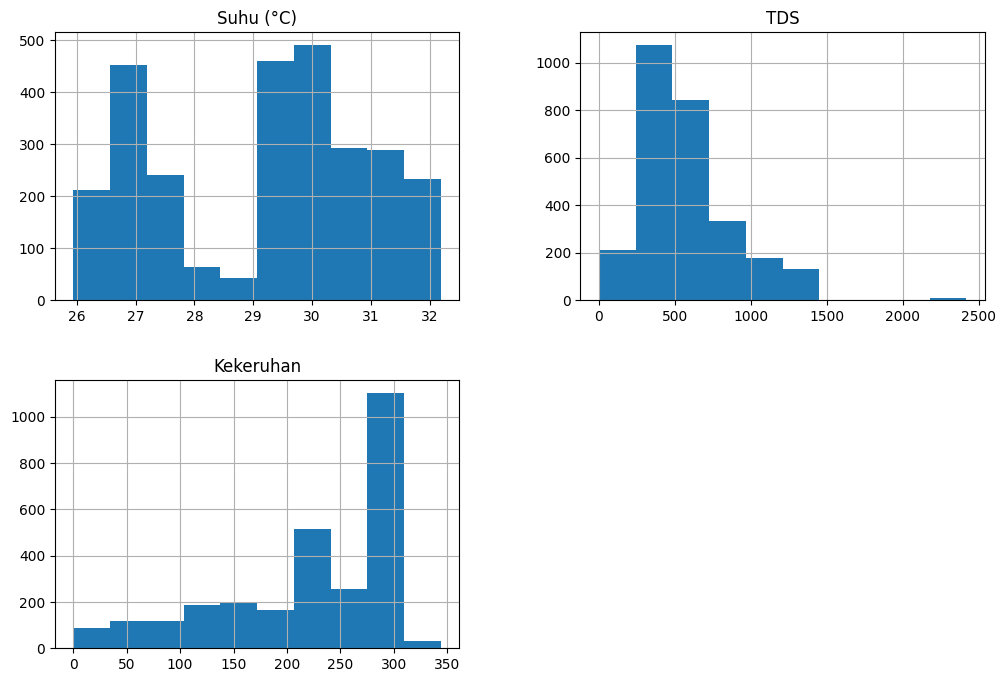

In [ ]:
display(df.select_dtypes(include="number").hist(figsize=(12, 8)))

# Data Cleaning

In [ ]:
# ============================================================
# 1. MENYIAPKAN DATASET DAN MEMERIKSA KOLOM
# ============================================================

import pandas as pd
import numpy as np

# Kolom waktu yang masih tersedia pada file Excel.
# Catatan: "Waktu Aktual" dipertahankan sebagai metadata,
# tetapi tidak dipakai untuk menghapus baris karena asalnya belum terverifikasi.
kolom_waktu = "Waktu Aktual"
kolom_parameter = ["Suhu (°C)", "pH", "TDS", "Kekeruhan"]
kolom_wajib = ["Tanggal", "Sesi", kolom_waktu] + kolom_parameter

kolom_tidak_ada = [
    kolom for kolom in kolom_wajib
    if kolom not in df.columns
]
if kolom_tidak_ada:
    raise ValueError(
        f"Kolom tidak ditemukan: {kolom_tidak_ada}. "
        f"Kolom yang tersedia: {df.columns.tolist()}"
    )

# Simpan data awal tanpa perubahan dan buat salinan untuk cleaning.
df_raw = df.copy()
df_cleaning = df.copy()
jumlah_data_awal = len(df_cleaning)

print("Jumlah data awal:", jumlah_data_awal)
print("Kolom dataset:", df_cleaning.columns.tolist())
display(df_cleaning.head())

Jumlah data awal: 2790
Kolom dataset: ['Tanggal', 'Sesi', 'Waktu Aktual', 'Suhu (°C)', 'pH', 'TDS', 'Kekeruhan']


,Tanggal,Sesi,Waktu Aktual,Suhu (°C),pH,TDS,Kekeruhan
0,2026-09-15,07:00,2026-09-15 07:01:57.000,25.94,"6,75",728.69,145.21
1,2026-09-15,07:00,2026-09-15 07:02:28.000,25.94,"6,75",728.69,145.21
2,2026-09-15,07:00,2026-09-15 07:02:57.004,25.94,"6,75",688.40,142.87
3,2026-09-15,07:00,2026-09-15 07:03:27.198,25.94,"6,75",670.59,123.75
4,2026-09-15,07:00,2026-09-15 07:03:57.493,25.94,"6,75",650.11,103.29


In [ ]:

# ============================================================
# 2. MEMERIKSA DAN MENANGANI DUPLIKAT
# ============================================================

jumlah_duplikat = df_cleaning.duplicated().sum()

print("Duplikat sebelum dibersihkan:", jumlah_duplikat)

df_cleaning = df_cleaning.drop_duplicates().copy()

print("Duplikat setelah dibersihkan:", df_cleaning.duplicated().sum())
print("Jumlah data setelah penghapusan duplikat:", len(df_cleaning))


Duplikat sebelum dibersihkan: 0
Duplikat setelah dibersihkan: 0
Jumlah data setelah penghapusan duplikat: 2790


In [ ]:
# ============================================================
# 3. MENGUBAH TIPE DATA
# ============================================================

# Ubah kolom tanggal dan waktu menjadi datetime untuk pemeriksaan metadata.
df_cleaning["Tanggal"] = pd.to_datetime(
    df_cleaning["Tanggal"], errors="coerce"
)
df_cleaning[kolom_waktu] = pd.to_datetime(
    df_cleaning[kolom_waktu], errors="coerce"
)

# Ubah empat parameter kualitas air menjadi numerik.
for kolom in kolom_parameter:
    if kolom == "pH":
        # Menangani format desimal dengan koma, misalnya "6,44".
        df_cleaning[kolom] = (
            df_cleaning[kolom].astype(str).str.strip()
            .str.replace(",", ".", regex=False)
        )
    df_cleaning[kolom] = pd.to_numeric(
        df_cleaning[kolom], errors="coerce"
    )

print("Tipe data setelah konversi:")
display(df_cleaning[["Tanggal", kolom_waktu] + kolom_parameter].dtypes.to_frame("Tipe Data"))
print("\nTanggal tidak terbaca:", df_cleaning["Tanggal"].isna().sum())
print("Waktu Aktual tidak terbaca:", df_cleaning[kolom_waktu].isna().sum())
print("pH kosong:", df_cleaning["pH"].isna().sum())
print("Contoh nilai pH:", df_cleaning["pH"].head(10).tolist())

Tipe data setelah konversi:


,Tipe Data
Tanggal,datetime64[ns]
Waktu Aktual,datetime64[ns]
Suhu (°C),float64
pH,float64
TDS,float64
Kekeruhan,float64



Tanggal tidak terbaca: 0
Waktu Aktual tidak terbaca: 0
pH kosong: 15
Contoh nilai pH: [6.75, 6.75, 6.75, 6.75, 6.75, 6.75, 6.36, 6.36, 6.36, 6.35]


In [ ]:

# ============================================================
# 4. MEMERIKSA MISSING VALUE
# ============================================================

print("Missing value sebelum penanganan:")

display(
    df_cleaning[kolom_wajib]
    .isna()
    .sum()
    .rename("Jumlah Missing Value")
    .to_frame()
)


Missing value sebelum penanganan:


,Jumlah Missing Value
Tanggal,0
Sesi,0
Waktu Aktual,0
Suhu (°C),12
pH,15
TDS,9
Kekeruhan,13


In [ ]:
# ============================================================
# 5.A. MEMERIKSA ANOMALI NILAI SENSOR
# ============================================================

batas_pemeriksaan = {
    "Suhu (°C)": (0, 50),
    "pH": (0, 14),
    "TDS": (0, None),
    "Kekeruhan": (0, None)
}

daftar_anomali = []

for kolom, (batas_bawah, batas_atas) in batas_pemeriksaan.items():
    if batas_bawah is not None:
        mask = df_cleaning[kolom] < batas_bawah
        for idx in df_cleaning.index[mask]:
            daftar_anomali.append({
                "Index": idx,
                "Waktu Aktual": df_cleaning.at[idx, kolom_waktu],
                "Parameter": kolom,
                "Nilai": df_cleaning.at[idx, kolom],
                "Keterangan": "Di bawah batas pemeriksaan"
            })
    if batas_atas is not None:
        mask = df_cleaning[kolom] > batas_atas
        for idx in df_cleaning.index[mask]:
            daftar_anomali.append({
                "Index": idx,
                "Waktu Aktual": df_cleaning.at[idx, kolom_waktu],
                "Parameter": kolom,
                "Nilai": df_cleaning.at[idx, kolom],
                "Keterangan": "Di atas batas pemeriksaan"
            })

df_anomali = pd.DataFrame(daftar_anomali)
print("Jumlah temuan anomali:", len(df_anomali))
if not df_anomali.empty:
    display(df_anomali.head(20))
else:
    print("Tidak ditemukan anomali berdasarkan batas pemeriksaan.")

Jumlah temuan anomali: 0
Tidak ditemukan anomali berdasarkan batas pemeriksaan.


In [ ]:
#5.B.Menangani nilai yang sudah terbukti tidak valid
kolom_batas = {
    "Suhu (°C)": (0, 50),
    "pH": (0, 14),
    "TDS": (0, None),
    "Kekeruhan": (0, None)
}

for kolom, (bawah, atas) in kolom_batas.items():
    if bawah is not None:
        df_cleaning.loc[
            df_cleaning[kolom] < bawah, kolom
        ] = np.nan

    if atas is not None:
        df_cleaning.loc[
            df_cleaning[kolom] > atas, kolom
        ] = np.nan

In [ ]:
# ============================================================
# 6. PEMERIKSAAN INFORMASI TANGGAL, SESI, DAN WAKTU AKTUAL
# ============================================================

# Waktu Aktual merupakan timestamp pembacaan sensor yang sebenarnya.
# Pengukuran dilakukan setiap sekitar 30 detik dalam masing-masing sesi.
# Timestamp digunakan untuk mengurutkan data dan interpolasi berbasis waktu.
# Data tetap dipisahkan menurut Tanggal dan Sesi agar interpolasi tidak
# menghubungkan sesi pagi, siang, dan sore.

def normalisasi_sesi(nilai):
    if pd.isna(nilai):
        return np.nan
    teks = str(nilai).strip()
    bagian = teks.split(":")
    if len(bagian) >= 2:
        try:
            return f"{int(bagian[0]):02d}:{int(bagian[1]):02d}"
        except ValueError:
            return teks
    return teks

df_cleaning["Sesi"] = df_cleaning["Sesi"].apply(normalisasi_sesi)
df_cleaning[kolom_waktu] = pd.to_datetime(
    df_cleaning[kolom_waktu], errors="coerce"
)

sesi_diizinkan = ["07:00", "12:00", "17:00"]
df_sesi_tidak_dikenal = df_cleaning[
    ~df_cleaning["Sesi"].isin(sesi_diizinkan)
].copy()
df_tanggal_invalid = df_cleaning[df_cleaning["Tanggal"].isna()].copy()
df_waktu_invalid = df_cleaning[df_cleaning[kolom_waktu].isna()].copy()

print("Jumlah data pada tahap ini:", len(df_cleaning))
print("Tanggal tidak terbaca:", len(df_tanggal_invalid))
print("Waktu Aktual tidak terbaca:", len(df_waktu_invalid))
print("Sesi di luar daftar yang diharapkan:", len(df_sesi_tidak_dikenal))

if not df_sesi_tidak_dikenal.empty:
    display(df_sesi_tidak_dikenal[["Tanggal", "Sesi", kolom_waktu]].head(20))
if not df_waktu_invalid.empty:
    display(df_waktu_invalid[["Tanggal", "Sesi", kolom_waktu]].head(20))

# Urutkan data dengan timestamp aktual, tetapi pertahankan indeks agar
# pelacakan posisi data asli tetap dapat dilakukan.
df_cleaning = df_cleaning.sort_values(
    ["Tanggal", "Sesi", kolom_waktu]
).copy()

# Pemeriksaan interval aktual antarpembacaan dalam sesi.
df_interval_waktu = df_cleaning.sort_values(
    ["Tanggal", "Sesi", kolom_waktu
]).copy()
df_interval_waktu["Interval (detik)"] = (
    df_interval_waktu.groupby(["Tanggal", "Sesi"])[kolom_waktu]
    .diff().dt.total_seconds()
)
print("\\nRingkasan interval antar pembacaan dalam sesi (detik):")
display(df_interval_waktu["Interval (detik)"].describe().to_frame())


Jumlah data pada tahap ini: 2790
Tanggal tidak terbaca: 0
Waktu Aktual tidak terbaca: 0
Sesi di luar daftar yang diharapkan: 0
\nRingkasan interval antar pembacaan dalam sesi (detik):


,Interval (detik)
count,2697.000000
mean,29.782322
std,3.431386
min,5.482000
25%,29.663000
50%,30.000000
75%,30.306000
max,123.358000


### Catatan penggunaan waktu aktual

In [ ]:
# ============================================================
# 7. VALIDASI JUMLAH PEMBACAAN DAN DURASI AKTUAL SETIAP SESI
# ============================================================

# Jadwal nominal sesi digunakan sebagai acuan untuk menghitung keterlambatan
# mulai. Karena operator dapat terlambat menghubungkan ESP32, durasi 15 menit
# dihitung dari timestamp pembacaan pertama yang benar-benar terekam.
jadwal_sesi = {
    "07:00": "07:00:00",
    "12:00": "12:00:00",
    "17:00": "17:00:00"
}
target_pembacaan_per_sesi = 30
interval_target_detik = 30
durasi_target_detik = 15 * 60

df_validasi_sesi = df_cleaning.sort_values(
    ["Tanggal", "Sesi", kolom_waktu]
).copy()

hasil_validasi_sesi = []
for (tanggal, sesi), bagian in df_validasi_sesi.groupby(
    ["Tanggal", "Sesi"], sort=True, dropna=False
):
    bagian = bagian.sort_values(kolom_waktu)
    waktu_valid = bagian[kolom_waktu].dropna()

    if len(waktu_valid) == 0 or pd.isna(tanggal) or sesi not in jadwal_sesi:
        waktu_pertama = pd.NaT
        waktu_terakhir = pd.NaT
        durasi_aktual = np.nan
        keterlambatan_detik = np.nan
        interval_median = np.nan
        interval_min = np.nan
        interval_maks = np.nan
        jumlah_timestamp_duplikat = np.nan
        dalam_durasi = np.nan
    else:
        waktu_pertama = waktu_valid.iloc[0]
        waktu_terakhir = waktu_valid.iloc[-1]
        durasi_aktual = (waktu_terakhir - waktu_pertama).total_seconds()

        waktu_jadwal = pd.to_datetime(
            f"{pd.Timestamp(tanggal).date()} {jadwal_sesi[sesi]}"
        )
        keterlambatan_detik = (
            waktu_pertama - waktu_jadwal
        ).total_seconds()

        interval = waktu_valid.sort_values().diff().dt.total_seconds().dropna()
        interval_median = interval.median() if len(interval) else np.nan
        interval_min = interval.min() if len(interval) else np.nan
        interval_maks = interval.max() if len(interval) else np.nan
        jumlah_timestamp_duplikat = int(waktu_valid.duplicated().sum())

        # Jendela pembacaan diperiksa dari pembacaan aktual pertama.
        # Toleransi kecil 30 detik diberikan untuk variasi timestamp.
        dalam_durasi = bool(
            durasi_aktual <= durasi_target_detik + interval_target_detik
        )

    jumlah_baris = len(bagian)
    jumlah_timestamp = len(waktu_valid)
    hasil_validasi_sesi.append({
        "Tanggal": tanggal,
        "Sesi": sesi,
        "Jumlah Baris": jumlah_baris,
        "Jumlah Timestamp Valid": jumlah_timestamp,
        "Target Pembacaan": target_pembacaan_per_sesi,
        "Selisih dari Target": jumlah_timestamp - target_pembacaan_per_sesi,
        "Waktu Aktual Pertama": waktu_pertama,
        "Waktu Aktual Terakhir": waktu_terakhir,
        "Keterlambatan Mulai (detik)": keterlambatan_detik,
        "Durasi Aktual (menit)": (
            durasi_aktual / 60 if pd.notna(durasi_aktual) else np.nan
        ),
        "Median Interval (detik)": interval_median,
        "Interval Minimum (detik)": interval_min,
        "Interval Maksimum (detik)": interval_maks,
        "Timestamp Duplikat": jumlah_timestamp_duplikat,
        "Dalam Durasi 15 Menit (+ toleransi)": dalam_durasi
    })

df_ringkasan_sesi = pd.DataFrame(hasil_validasi_sesi)
print("Ringkasan jumlah pembacaan dan waktu aktual per tanggal-sesi:")
display(df_ringkasan_sesi)

print("\\nRekap jumlah sesi:")
print("Jumlah kelompok tanggal-sesi:", len(df_ringkasan_sesi))
print("Sesi dengan tepat 30 timestamp:", int(
    (df_ringkasan_sesi["Jumlah Timestamp Valid"] == 30).sum()
))
print("Sesi dengan kurang dari 30 timestamp:", int(
    (df_ringkasan_sesi["Jumlah Timestamp Valid"] < 30).sum()
))
print("Sesi dengan lebih dari 30 timestamp:", int(
    (df_ringkasan_sesi["Jumlah Timestamp Valid"] > 30).sum()
))

# Periksa timestamp duplikat dalam satu tanggal-sesi.
duplikat_waktu_sesi = df_validasi_sesi[
    df_validasi_sesi.duplicated(
        subset=["Tanggal", "Sesi", kolom_waktu], keep=False
    )
].sort_values(["Tanggal", "Sesi", kolom_waktu])

print("\\nJumlah baris dengan timestamp duplikat dalam tanggal-sesi:",
      len(duplikat_waktu_sesi))
if not duplikat_waktu_sesi.empty:
    display(duplikat_waktu_sesi[
        ["Tanggal", "Sesi", kolom_waktu] + kolom_parameter
    ])

# Interval aktual tetap diperiksa. Variasi interval tidak otomatis dihapus.
df_interval_sesi = df_validasi_sesi.copy()
df_interval_sesi["Interval (detik)"] = (
    df_interval_sesi.groupby(["Tanggal", "Sesi"])[kolom_waktu]
    .diff().dt.total_seconds()
)
print("\\nDistribusi interval antar pembacaan (detik):")
display(df_interval_sesi["Interval (detik)"].describe().to_frame())

print(
    "\\nCatatan: keterlambatan mulai tidak otomatis membuat data salah sesi. "
    "Kolom Sesi tetap menjadi penanda sesi pengamatan; waktu aktual dipakai "
    "untuk menghitung keterlambatan, durasi, dan interval pembacaan."
)


Ringkasan jumlah pembacaan dan waktu aktual per tanggal-sesi:


,Tanggal,Sesi,Jumlah Baris,Jumlah Timestamp Valid,Target Pembacaan,Selisih dari Target,Waktu Aktual Pertama,Waktu Aktual Terakhir,Keterlambatan Mulai (detik),Durasi Aktual (menit),Median Interval (detik),Interval Minimum (detik),Interval Maksimum (detik),Timestamp Duplikat,Dalam Durasi 15 Menit (+ toleransi)
0,2026-09-15,07:00,30,30,30,0,2026-09-15 07:01:57.000,2026-09-15 07:16:27.684,117.000,14.511400,30.132,29.004,31.000,0,True
1,2026-09-15,12:00,30,30,30,0,2026-09-15 12:00:25.524,2026-09-15 12:14:54.304,25.524,14.479667,29.998,28.383,31.724,0,True
2,2026-09-15,17:00,30,30,30,0,2026-09-15 17:00:51.826,2026-09-15 17:15:21.943,51.826,14.501950,30.054,28.778,30.887,0,True
3,2026-09-16,07:00,30,30,30,0,2026-09-16 07:00:43.636,2026-09-16 07:15:13.485,43.636,14.497483,30.105,28.933,30.812,0,True
4,2026-09-16,12:00,30,30,30,0,2026-09-16 12:00:23.162,2026-09-16 12:14:52.384,23.162,14.487033,30.116,28.707,31.455,0,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
88,2026-10-14,12:00,30,30,30,0,2026-10-14 12:06:37.716,2026-10-14 12:21:08.142,397.716,14.507100,30.111,19.462,40.031,0,True
89,2026-10-14,17:00,30,30,30,0,2026-10-14 16:58:43.173,2026-10-14 17:13:13.727,-76.827,14.509233,29.948,27.691,32.482,0,True
90,2026-10-15,07:00,30,30,30,0,2026-10-15 07:06:00.746,2026-10-15 07:21:01.173,360.746,15.007117,30.010,26.463,59.876,0,True
91,2026-10-15,12:00,30,30,30,0,2026-10-15 12:03:28.678,2026-10-15 12:17:29.436,208.678,14.012633,29.816,13.367,32.110,0,True


\nRekap jumlah sesi:
Jumlah kelompok tanggal-sesi: 93
Sesi dengan tepat 30 timestamp: 93
Sesi dengan kurang dari 30 timestamp: 0
Sesi dengan lebih dari 30 timestamp: 0
\nJumlah baris dengan timestamp duplikat dalam tanggal-sesi: 0
\nDistribusi interval antar pembacaan (detik):


,Interval (detik)
count,2697.000000
mean,29.782322
std,3.431386
min,5.482000
25%,29.663000
50%,30.000000
75%,30.306000
max,123.358000


\nCatatan: keterlambatan mulai tidak otomatis membuat data salah sesi. Kolom Sesi tetap menjadi penanda sesi pengamatan; waktu aktual dipakai untuk menghitung keterlambatan, durasi, dan interval pembacaan.


### Interpretasi validasi sesi

In [ ]:
# ============================================================
# 7A. QUALITY GATE SEBELUM INTERPOLASI
# ============================================================

# Pastikan identitas sesi dan timestamp dapat digunakan.
if df_cleaning["Tanggal"].isna().any():
    raise ValueError("Terdapat Tanggal kosong/tidak valid.")
if df_cleaning["Sesi"].isna().any() or not df_cleaning["Sesi"].isin(
    ["07:00", "12:00", "17:00"]
).all():
    raise ValueError("Terdapat label Sesi kosong atau di luar jadwal.")
if df_cleaning[kolom_waktu].isna().any():
    raise ValueError("Terdapat Waktu Aktual kosong/tidak valid.")

# Satu timestamp hanya boleh muncul satu kali dalam satu tanggal-sesi.
duplikat_timestamp = df_cleaning.duplicated(
    subset=["Tanggal", "Sesi", kolom_waktu], keep=False
)
if duplikat_timestamp.any():
    display(df_cleaning.loc[
        duplikat_timestamp,
        ["Tanggal", "Sesi", kolom_waktu] + kolom_parameter
    ])
    raise ValueError(
        "Ada timestamp duplikat dalam kelompok tanggal-sesi. "
        "Periksa data sumber sebelum melanjutkan interpolasi."
    )

print(
    "Quality gate lolos: Tanggal, Sesi, dan Waktu Aktual valid; "
    "tidak ditemukan timestamp duplikat."
)


Quality gate lolos: Tanggal, Sesi, dan Waktu Aktual valid; tidak ditemukan timestamp duplikat.


In [ ]:

# ============================================================
# 8. MEMERIKSA BARIS DENGAN SEMUA PARAMETER KOSONG
# ============================================================

mask_semua_kosong = df_cleaning[kolom_parameter].isna().all(axis=1)

df_baris_kosong = df_cleaning[
    mask_semua_kosong
].copy()

print("Baris dengan semua parameter kosong:", len(df_baris_kosong))

df_cleaning = df_cleaning[
    ~mask_semua_kosong
].copy()

print("Jumlah data setelah penanganan:", len(df_cleaning))


Baris dengan semua parameter kosong: 4
Jumlah data setelah penanganan: 2786


## Perbandingan metode penanganan missing value

In [ ]:
# ============================================================
# PERBANDINGAN METODE IMPUTASI: MEDIAN vs INTERPOLASI vs KNN
# ============================================================

from sklearn.metrics import mean_absolute_error
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler

jumlah_pengulangan = 30
proporsi_uji = 0.20
jumlah_tetangga_knn = 5  # Tetap sesuai keputusan sebelumnya; bukan Manhattan k=15.

# Data sumber untuk uji; belum dilakukan imputasi.\n# Pengelompokan tetap berdasarkan Tanggal-Sesi, bukan batas\n# jam yang dihitung ulang dari timestamp, sehingga keterlambatan\n# mulai ESP32 tidak memindahkan baris ke sesi lain.
df_uji_imputasi = df_cleaning.copy().sort_values(
    ["Tanggal", "Sesi", kolom_waktu]
).copy()

if df_uji_imputasi[kolom_waktu].isna().any():
    raise ValueError(
        "Ada Waktu Aktual yang kosong/tidak terbaca. Perbaiki timestamp "
        "terlebih dahulu sebelum melakukan interpolasi berbasis waktu."
    )

grup_imputasi = [
    np.asarray(indeks, dtype=int)
    for indeks in df_uji_imputasi.groupby(
        ["Tanggal", "Sesi"], sort=False, dropna=False
    ).indices.values()
]

hasil_perbandingan = []

for kolom in kolom_parameter:
    mae_median_semua, mae_interpolasi_semua, mae_knn_semua = [], [], []
    jumlah_posisi_diuji = []

    nilai_asli = df_uji_imputasi[kolom].to_numpy(dtype=float)

    # Kandidat uji adalah titik valid yang memiliki tetangga valid
    # sebelum dan sesudahnya dalam sesi yang sama.
    kandidat = []
    for indeks_grup in grup_imputasi:
        for urutan in range(1, len(indeks_grup) - 1):
            posisi = indeks_grup[urutan]
            if (
                np.isfinite(nilai_asli[posisi])
                and np.isfinite(nilai_asli[indeks_grup[urutan - 1]])
                and np.isfinite(nilai_asli[indeks_grup[urutan + 1]])
            ):
                kandidat.append(posisi)

    for seed in range(jumlah_pengulangan):
        rng = np.random.default_rng(seed)
        if len(kandidat) < 5:
            continue

        jumlah_mask = max(1, int(round(len(kandidat) * proporsi_uji)))
        posisi_uji = np.sort(
            rng.choice(kandidat, size=min(jumlah_mask, len(kandidat)), replace=False)
        )

        data_masked = df_uji_imputasi[kolom_parameter].copy()
        data_masked.loc[df_uji_imputasi.index[posisi_uji], kolom] = np.nan
        aktual = nilai_asli[posisi_uji]

        # A. Median
        median_kolom = data_masked[kolom].median()
        prediksi_median = np.full(len(posisi_uji), median_kolom)

        # B. Interpolasi berbasis waktu aktual dalam setiap sesi.
        data_interp = pd.Series(
            data_masked[kolom].to_numpy(dtype=float),
            index=df_uji_imputasi.index
        )
        for indeks_grup in grup_imputasi:
            indeks_asli = df_uji_imputasi.index[indeks_grup]
            waktu = pd.DatetimeIndex(
                df_uji_imputasi.loc[indeks_asli, kolom_waktu]
            )
            bagian = pd.Series(
                data_interp.loc[indeks_asli].to_numpy(dtype=float),
                index=waktu
            )
            hasil = bagian.interpolate(method="time", limit_area="inside")
            data_interp.loc[indeks_asli] = hasil.to_numpy()

        prediksi_interpolasi = data_interp.loc[
            df_uji_imputasi.index[posisi_uji]
        ].to_numpy(dtype=float)

        # C. KNN dengan standardisasi fitur.
        scaler_uji = StandardScaler()
        data_scaled = scaler_uji.fit_transform(data_masked[kolom_parameter])
        imputer_uji = KNNImputer(
            n_neighbors=jumlah_tetangga_knn,
            weights="distance"
        )
        hasil_knn_scaled = imputer_uji.fit_transform(data_scaled)
        hasil_knn = scaler_uji.inverse_transform(hasil_knn_scaled)
        indeks_fitur = kolom_parameter.index(kolom)
        prediksi_knn = hasil_knn[posisi_uji, indeks_fitur]

        valid = (
            np.isfinite(aktual)
            & np.isfinite(prediksi_median)
            & np.isfinite(prediksi_interpolasi)
            & np.isfinite(prediksi_knn)
        )
        if valid.sum() == 0:
            continue

        mae_median_semua.append(
            mean_absolute_error(aktual[valid], prediksi_median[valid])
        )
        mae_interpolasi_semua.append(
            mean_absolute_error(aktual[valid], prediksi_interpolasi[valid])
        )
        mae_knn_semua.append(
            mean_absolute_error(aktual[valid], prediksi_knn[valid])
        )
        jumlah_posisi_diuji.append(int(valid.sum()))

    hasil_perbandingan.append({
        "Parameter": kolom,
        "MAE Median": np.mean(mae_median_semua) if mae_median_semua else np.nan,
        "MAE Interpolasi": np.mean(mae_interpolasi_semua) if mae_interpolasi_semua else np.nan,
        "MAE KNN Imputation": np.mean(mae_knn_semua) if mae_knn_semua else np.nan,
        "Rata-rata Posisi Uji Sama": (
            round(np.mean(jumlah_posisi_diuji), 1) if jumlah_posisi_diuji else 0
        ),
        "Pengulangan Berhasil": len(mae_knn_semua)
    })

df_perbandingan_imputasi = pd.DataFrame(hasil_perbandingan)
print("Perbandingan MAE tiga metode pada posisi uji yang sama:")
display(df_perbandingan_imputasi.round(4))

print(
    "\\nCatatan: interpolasi diuji pada posisi yang memiliki data valid "
    "di kedua sisi dalam sesi yang sama. Hasil uji ini tidak berarti "
    "missing value pada awal/akhir sesi dapat diinterpolasi."
)


Perbandingan MAE tiga metode pada posisi uji yang sama:


,Parameter,MAE Median,MAE Interpolasi,MAE KNN Imputation,Rata-rata Posisi Uji Sama,Pengulangan Berhasil
0,Suhu (°C),1.5103,0.0378,0.0378,517.0,30
1,pH,0.1793,0.0403,0.0403,516.0,30
2,TDS,220.6279,33.3903,33.3903,518.0,30
3,Kekeruhan,63.8827,12.3310,12.3310,517.0,30


\nCatatan: interpolasi diuji pada posisi yang memiliki data valid di kedua sisi dalam sesi yang sama. Hasil uji ini tidak berarti missing value pada awal/akhir sesi dapat diinterpolasi.


### Prinsip pemilihan dan penerapan imputasi

### Audit posisi missing value sebelum imputasi

In [ ]:
# ============================================================
# AUDIT JARAK WAKTU DI SEKITAR SETIAP MISSING VALUE
# ============================================================

# Gunakan data asli sebelum imputasi agar posisi missing tidak tertutup hasil pengisian.
df_audit_missing = df_cleaning.copy()
baris_audit = []

for kolom in kolom_parameter:
    for (tanggal, sesi), bagian in df_audit_missing.groupby(
        ["Tanggal", "Sesi"], sort=False, dropna=False
    ):
        bagian = bagian.sort_values(kolom_waktu)
        indeks = bagian.index.to_list()
        waktu = pd.to_datetime(bagian[kolom_waktu]).to_list()
        nilai = bagian[kolom].to_numpy(dtype=float)
        posisi_kosong = np.flatnonzero(~np.isfinite(nilai))

        for pos in posisi_kosong:
            prev_pos = next((j for j in range(pos - 1, -1, -1)
                             if np.isfinite(nilai[j])), None)
            next_pos = next((j for j in range(pos + 1, len(nilai))
                             if np.isfinite(nilai[j])), None)

            t_kosong = waktu[pos]
            t_prev = waktu[prev_pos] if prev_pos is not None else pd.NaT
            t_next = waktu[next_pos] if next_pos is not None else pd.NaT
            jarak_kiri = (t_kosong - t_prev).total_seconds() if prev_pos is not None else np.nan
            jarak_kanan = (t_next - t_kosong).total_seconds() if next_pos is not None else np.nan
            rentang_pembatas = (t_next - t_prev).total_seconds() if prev_pos is not None and next_pos is not None else np.nan

            if prev_pos is not None and next_pos is not None:
                status = "Dapat diinterpolasi (diapit data valid)"
                penilaian = "Perlu ditinjau" if rentang_pembatas > 90 else "Rentang <= 90 detik"
            else:
                status = "Tidak dapat diinterpolasi (batas sesi)"
                penilaian = "Gunakan metode alternatif"

            baris_audit.append({
                "Indeks Data": indeks[pos],
                "Tanggal": tanggal,
                "Sesi": sesi,
                "Waktu Aktual Missing": t_kosong,
                "Parameter": kolom,
                "Waktu Valid Sebelumnya": t_prev,
                "Waktu Valid Sesudahnya": t_next,
                "Jarak ke Sebelumnya (detik)": jarak_kiri,
                "Jarak ke Sesudahnya (detik)": jarak_kanan,
                "Rentang antar-pembatas (detik)": rentang_pembatas,
                "Status Interpolasi": status,
                "Catatan Pemeriksaan": penilaian
            })

df_audit_missing = pd.DataFrame(baris_audit)
print("Jumlah sel missing value yang diaudit:", len(df_audit_missing))
if not df_audit_missing.empty:
    display(df_audit_missing.sort_values(
        ["Tanggal", "Sesi", "Waktu Aktual Missing", "Parameter"]
    ).reset_index(drop=True))
    print("Ringkasan status posisi missing value:")
    display(df_audit_missing.groupby(
        ["Parameter", "Status Interpolasi", "Catatan Pemeriksaan"],
        dropna=False
    ).size().reset_index(name="Jumlah Sel"))


Jumlah sel missing value yang diaudit: 33


,Indeks Data,Tanggal,Sesi,Waktu Aktual Missing,Parameter,Waktu Valid Sebelumnya,Waktu Valid Sesudahnya,Jarak ke Sebelumnya (detik),Jarak ke Sesudahnya (detik),Rentang antar-pembatas (detik),Status Interpolasi,Catatan Pemeriksaan
0,80,2026-09-15,17:00,2026-09-15 17:10:51.861,TDS,2026-09-15 17:10:21.504,2026-09-15 17:11:21.749,30.357,29.888,60.245,Dapat diinterpolasi (diapit data valid),Rentang <= 90 detik
1,90,2026-09-16,07:00,2026-09-16 07:00:43.636,Kekeruhan,NaT,2026-09-16 07:01:43.689,NaN,60.053,NaN,Tidak dapat diinterpolasi (batas sesi),Gunakan metode alternatif
2,90,2026-09-16,07:00,2026-09-16 07:00:43.636,TDS,NaT,2026-09-16 07:01:43.689,NaN,60.053,NaN,Tidak dapat diinterpolasi (batas sesi),Gunakan metode alternatif
3,90,2026-09-16,07:00,2026-09-16 07:00:43.636,pH,NaT,2026-09-16 07:01:43.689,NaN,60.053,NaN,Tidak dapat diinterpolasi (batas sesi),Gunakan metode alternatif
4,91,2026-09-16,07:00,2026-09-16 07:01:13.658,Kekeruhan,NaT,2026-09-16 07:01:43.689,NaN,30.031,NaN,Tidak dapat diinterpolasi (batas sesi),Gunakan metode alternatif
5,91,2026-09-16,07:00,2026-09-16 07:01:13.658,TDS,NaT,2026-09-16 07:01:43.689,NaN,30.031,NaN,Tidak dapat diinterpolasi (batas sesi),Gunakan metode alternatif
6,91,2026-09-16,07:00,2026-09-16 07:01:13.658,pH,NaT,2026-09-16 07:01:43.689,NaN,30.031,NaN,Tidak dapat diinterpolasi (batas sesi),Gunakan metode alternatif
7,823,2026-09-24,07:00,2026-09-24 07:06:38.253,Kekeruhan,2026-09-24 07:06:08.126,2026-09-24 07:07:38.050,30.127,59.797,89.924,Dapat diinterpolasi (diapit data valid),Rentang <= 90 detik
8,824,2026-09-24,07:00,2026-09-24 07:07:08.108,Kekeruhan,2026-09-24 07:06:08.126,2026-09-24 07:07:38.050,59.982,29.942,89.924,Dapat diinterpolasi (diapit data valid),Rentang <= 90 detik
9,1442,2026-10-01,07:00,2026-10-01 07:08:12.675,pH,2026-10-01 07:07:43.081,2026-10-01 07:08:42.367,29.594,29.692,59.286,Dapat diinterpolasi (diapit data valid),Rentang <= 90 detik


Ringkasan status posisi missing value:


,Parameter,Status Interpolasi,Catatan Pemeriksaan,Jumlah Sel
0,Kekeruhan,Dapat diinterpolasi (diapit data valid),Rentang <= 90 detik,5
1,Kekeruhan,Tidak dapat diinterpolasi (batas sesi),Gunakan metode alternatif,4
2,Suhu (°C),Dapat diinterpolasi (diapit data valid),Perlu ditinjau,8
3,TDS,Dapat diinterpolasi (diapit data valid),Rentang <= 90 detik,3
4,TDS,Tidak dapat diinterpolasi (batas sesi),Gunakan metode alternatif,2
5,pH,Dapat diinterpolasi (diapit data valid),Perlu ditinjau,7
6,pH,Dapat diinterpolasi (diapit data valid),Rentang <= 90 detik,2
7,pH,Tidak dapat diinterpolasi (batas sesi),Gunakan metode alternatif,2


In [ ]:
# ============================================================
# MEMILIH DAN MENERAPKAN IMPUTASI TANPA EKSTRAPOLASI
# ============================================================

# 1. Pilih metode alternatif berdasarkan MAE antara KNN Imputer (k=5, weights=distance) dan median.
#    Interpolasi diprioritaskan untuk missing value yang benar-benar
#    berada di bagian dalam sesi (ada pengamatan valid di kiri dan kanan).
metode_alternatif = {}

for _, baris in df_perbandingan_imputasi.iterrows():
    kolom = baris["Parameter"]
    kandidat_alternatif = {
        "knn": baris["MAE KNN Imputation"],
        "median": baris["MAE Median"]
    }
    kandidat_valid = {
        nama: nilai for nama, nilai in kandidat_alternatif.items()
        if pd.notna(nilai)
    }
    if not kandidat_valid:
        raise ValueError(f"Tidak ada hasil MAE yang valid untuk {kolom}.")
    metode_alternatif[kolom] = min(
        kandidat_valid, key=kandidat_valid.get
    )

print("Metode alternatif berdasarkan MAE (untuk posisi yang tidak bisa diinterpolasi):")
display(pd.DataFrame(
    [(k, v) for k, v in metode_alternatif.items()],
    columns=["Parameter", "Metode Alternatif"]
))

# 2. Simpan data sebelum penerapan imputasi.
df_sebelum_imputasi = df_cleaning.copy()
df_hasil_imputasi = df_sebelum_imputasi.copy()

# 3. Siapkan prediksi KNN satu kali dari data sebelum imputasi.
#    Hasil KNN hanya digunakan sebagai fallback jika interpolasi tidak mungkin.
scaler_final = StandardScaler()
data_final_scaled = scaler_final.fit_transform(
    df_sebelum_imputasi[kolom_parameter]
)
imputer_final = KNNImputer(
    n_neighbors=jumlah_tetangga_knn,
    weights="distance"
)
data_final_knn_scaled = imputer_final.fit_transform(data_final_scaled)
data_final_knn = pd.DataFrame(
    scaler_final.inverse_transform(data_final_knn_scaled),
    columns=kolom_parameter,
    index=df_sebelum_imputasi.index
)

# Pengelompokan interpolasi menggunakan identitas Tanggal-Sesi yang\n# telah tercatat. Timestamp aktual hanya menentukan jarak waktu antar\n# pembacaan; tidak digunakan untuk menggabungkan sesi berbeda.\n\n# 4. Fungsi interpolasi yang mengembalikan hasil hanya untuk missing
#    value di bagian dalam sesi. Tidak ada extrapolation di awal/akhir.
def interpolasi_dalam_sesi(data, kolom):
    hasil_kolom = data[kolom].copy()
    status_posisi = {}

    for (tanggal, sesi), indeks in data.groupby(
        ["Tanggal", "Sesi"], sort=False, dropna=False
    ).groups.items():
        indeks = list(indeks)
        bagian = data.loc[indeks, [kolom_waktu, kolom]].copy()
        bagian = bagian.sort_values(kolom_waktu)

        if bagian[kolom_waktu].isna().any():
            raise ValueError(
                f"Waktu Aktual kosong pada kelompok {tanggal} - {sesi}."
            )

        seri = pd.Series(
            bagian[kolom].to_numpy(dtype=float),
            index=pd.DatetimeIndex(bagian[kolom_waktu])
        )
        seri_interp = seri.interpolate(
            method="time",
            limit_area="inside"
        )

        # Cocokkan kembali berdasarkan indeks baris asli, bukan urutan global.
        indeks_urut = bagian.index
        nilai_interp = seri_interp.to_numpy()
        for idx, nilai_lama, nilai_baru in zip(
            indeks_urut,
            bagian[kolom].to_numpy(dtype=float),
            nilai_interp
        ):
            if pd.isna(nilai_lama):
                if np.isfinite(nilai_baru):
                    hasil_kolom.loc[idx] = nilai_baru
                    status_posisi[idx] = "Interpolasi (diapit data valid)"
                else:
                    status_posisi[idx] = "Tidak dapat diinterpolasi (awal/akhir sesi)"
    return hasil_kolom, status_posisi

# 5. Terapkan interpolasi terlebih dahulu, kemudian fallback untuk
#    missing value yang tersisa.
catatan_penanganan = []

for kolom in kolom_parameter:
    missing_awal = df_hasil_imputasi[kolom].isna()
    jumlah_awal = int(missing_awal.sum())

    if jumlah_awal == 0:
        continue

    hasil_interp, status_interp = interpolasi_dalam_sesi(
        df_hasil_imputasi, kolom
    )
    df_hasil_imputasi[kolom] = hasil_interp

    # Catat seluruh missing value awal beserta lokasi dan metode.
    for idx in df_hasil_imputasi.index[missing_awal]:
        if status_interp.get(idx) == "Interpolasi (diapit data valid)":
            metode_diterapkan = "Interpolasi berbasis Waktu Aktual"
        else:
            metode_diterapkan = metode_alternatif[kolom]
            if metode_diterapkan == "knn":
                nilai_fallback = data_final_knn.loc[idx, kolom]
            else:
                nilai_fallback = df_sebelum_imputasi[kolom].median()

            if pd.isna(df_hasil_imputasi.loc[idx, kolom]):
                df_hasil_imputasi.loc[idx, kolom] = nilai_fallback

        catatan_penanganan.append({
            "Indeks Data": idx,
            "Tanggal": df_hasil_imputasi.loc[idx, "Tanggal"],
            "Sesi": df_hasil_imputasi.loc[idx, "Sesi"],
            "Waktu Aktual": df_hasil_imputasi.loc[idx, kolom_waktu],
            "Parameter": kolom,
            "Kategori": status_interp.get(
                idx, "Tidak dapat diinterpolasi (awal/akhir sesi)"
            ),
            "Metode Diterapkan": metode_diterapkan
        })

df_log_imputasi = pd.DataFrame(catatan_penanganan)

# 6. Ringkasan berapa missing value yang dapat diinterpolasi dan fallback.
if not df_log_imputasi.empty:
    ringkasan_imputasi = (
        df_log_imputasi.groupby(
            ["Parameter", "Kategori", "Metode Diterapkan"],
            dropna=False
        ).size().reset_index(name="Jumlah Nilai")
    )
    print("Rincian penanganan missing value:")
    display(ringkasan_imputasi)

    print("Daftar posisi missing value yang ditangani:")
    display(
        df_log_imputasi.sort_values(
            ["Tanggal", "Sesi", "Waktu Aktual", "Parameter"]
        ).reset_index(drop=True)
    )
else:
    print("Tidak ditemukan missing value yang perlu ditangani.")

# 7. Verifikasi akhir; jangan lanjut jika masih ada nilai kosong.
print("\\nJumlah missing value sebelum dan sesudah imputasi:")
display(pd.DataFrame({
    "Parameter": kolom_parameter,
    "Missing Sebelum": [
        int(df_sebelum_imputasi[k].isna().sum()) for k in kolom_parameter
    ],
    "Missing Sesudah": [
        int(df_hasil_imputasi[k].isna().sum()) for k in kolom_parameter
    ]
}))

if df_hasil_imputasi[kolom_parameter].isna().any().any():
    raise ValueError(
        "Masih terdapat missing value setelah imputasi. "
        "Periksa log imputasi sebelum melanjutkan."
    )

# Ganti dataframe kerja dengan hasil imputasi yang sudah diverifikasi.
df_cleaning = df_hasil_imputasi.copy()

print("\\nTotal sel missing value awal:", len(df_log_imputasi))
print("Total sel missing value setelah imputasi:", int(
    df_cleaning[kolom_parameter].isna().sum().sum()
))


Metode alternatif berdasarkan MAE (untuk posisi yang tidak bisa diinterpolasi):


,Parameter,Metode Alternatif
0,Suhu (°C),knn
1,pH,knn
2,TDS,knn
3,Kekeruhan,knn


Rincian penanganan missing value:


,Parameter,Kategori,Metode Diterapkan,Jumlah Nilai
0,Kekeruhan,Interpolasi (diapit data valid),Interpolasi berbasis Waktu Aktual,5
1,Kekeruhan,Tidak dapat diinterpolasi (awal/akhir sesi),knn,4
2,Suhu (°C),Interpolasi (diapit data valid),Interpolasi berbasis Waktu Aktual,8
3,TDS,Interpolasi (diapit data valid),Interpolasi berbasis Waktu Aktual,3
4,TDS,Tidak dapat diinterpolasi (awal/akhir sesi),knn,2
5,pH,Interpolasi (diapit data valid),Interpolasi berbasis Waktu Aktual,9
6,pH,Tidak dapat diinterpolasi (awal/akhir sesi),knn,2


Daftar posisi missing value yang ditangani:


,Indeks Data,Tanggal,Sesi,Waktu Aktual,Parameter,Kategori,Metode Diterapkan
0,80,2026-09-15,17:00,2026-09-15 17:10:51.861,TDS,Interpolasi (diapit data valid),Interpolasi berbasis Waktu Aktual
1,90,2026-09-16,07:00,2026-09-16 07:00:43.636,Kekeruhan,Tidak dapat diinterpolasi (awal/akhir sesi),knn
2,90,2026-09-16,07:00,2026-09-16 07:00:43.636,TDS,Tidak dapat diinterpolasi (awal/akhir sesi),knn
3,90,2026-09-16,07:00,2026-09-16 07:00:43.636,pH,Tidak dapat diinterpolasi (awal/akhir sesi),knn
4,91,2026-09-16,07:00,2026-09-16 07:01:13.658,Kekeruhan,Tidak dapat diinterpolasi (awal/akhir sesi),knn
5,91,2026-09-16,07:00,2026-09-16 07:01:13.658,TDS,Tidak dapat diinterpolasi (awal/akhir sesi),knn
6,91,2026-09-16,07:00,2026-09-16 07:01:13.658,pH,Tidak dapat diinterpolasi (awal/akhir sesi),knn
7,823,2026-09-24,07:00,2026-09-24 07:06:38.253,Kekeruhan,Interpolasi (diapit data valid),Interpolasi berbasis Waktu Aktual
8,824,2026-09-24,07:00,2026-09-24 07:07:08.108,Kekeruhan,Interpolasi (diapit data valid),Interpolasi berbasis Waktu Aktual
9,1442,2026-10-01,07:00,2026-10-01 07:08:12.675,pH,Interpolasi (diapit data valid),Interpolasi berbasis Waktu Aktual


\nJumlah missing value sebelum dan sesudah imputasi:


,Parameter,Missing Sebelum,Missing Sesudah
0,Suhu (°C),8,0
1,pH,11,0
2,TDS,5,0
3,Kekeruhan,9,0


\nTotal sel missing value awal: 33
Total sel missing value setelah imputasi: 0


In [ ]:
# ============================================================
# 10. MEMVERIFIKASI MISSING VALUE SETELAH IMPUTASI
# ============================================================

# Hitung jumlah baris yang memiliki minimal satu missing value
# SEBELUM imputasi. Nilai ini digunakan pada tabel ringkasan cleaning.
jumlah_missing_tersisa = int(
    df_sebelum_imputasi[kolom_parameter].isna().any(axis=1).sum()
)

# Periksa hasil imputasi, bukan dataframe sebelum imputasi.
df_missing_tersisa = df_hasil_imputasi[
    df_hasil_imputasi[kolom_parameter].isna().any(axis=1)
].copy()

print("Baris yang masih memiliki parameter kosong setelah imputasi:", len(df_missing_tersisa))
print("Jumlah missing value per parameter setelah imputasi:")
display(
    df_hasil_imputasi[kolom_parameter].isna()
    .sum().rename("Jumlah Missing Value").to_frame()
)

if df_hasil_imputasi[kolom_parameter].isna().any().any():
    raise ValueError(
        "Dataset hasil imputasi masih memiliki missing value. "
        "Jangan lanjut ke tahap berikutnya."
    )

# Tetapkan hasil imputasi terverifikasi sebagai dataframe kerja final.
df_cleaning = df_hasil_imputasi.copy()

print("Verifikasi berhasil: seluruh parameter pada df_hasil_imputasi telah terisi.")
print("Jumlah baris dengan missing sebelum imputasi:", jumlah_missing_tersisa)
print("Jumlah missing value setelah imputasi:", int(
    df_cleaning[kolom_parameter].isna().sum().sum()
))


Baris yang masih memiliki parameter kosong setelah imputasi: 0
Jumlah missing value per parameter setelah imputasi:


,Jumlah Missing Value
Suhu (°C),0
pH,0
TDS,0
Kekeruhan,0


Verifikasi berhasil: seluruh parameter pada df_hasil_imputasi telah terisi.
Jumlah baris dengan missing sebelum imputasi: 24
Jumlah missing value setelah imputasi: 0


In [ ]:
# ============================================================
# 11. MENDETEKSI OUTLIER DENGAN METODE IQR
# ============================================================

hasil_iqr = []
daftar_outlier = []

for kolom in kolom_parameter:
    q1 = df_cleaning[kolom].quantile(0.25)
    q3 = df_cleaning[kolom].quantile(0.75)
    iqr = q3 - q1
    batas_bawah = q1 - 1.5 * iqr
    batas_atas = q3 + 1.5 * iqr

    mask_outlier = (
        (df_cleaning[kolom] < batas_bawah) |
        (df_cleaning[kolom] > batas_atas)
    )

    hasil_iqr.append({
        "Parameter": kolom,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Batas Bawah": batas_bawah,
        "Batas Atas": batas_atas,
        "Jumlah Outlier": int(mask_outlier.sum())
    })

    for idx in df_cleaning.index[mask_outlier]:
        daftar_outlier.append({
            "Index": idx,
            "Tanggal": df_cleaning.at[idx, "Tanggal"],
            "Sesi": df_cleaning.at[idx, "Sesi"],
            "Waktu Aktual": df_cleaning.at[idx, kolom_waktu],
            "Parameter": kolom,
            "Nilai": df_cleaning.at[idx, kolom],
            "Batas Bawah": batas_bawah,
            "Batas Atas": batas_atas
        })

df_hasil_iqr = pd.DataFrame(hasil_iqr)
df_outlier = pd.DataFrame(daftar_outlier)

# Outlier tidak otomatis dihapus; perlu ditinjau berdasarkan konteks pengukuran.
if not df_outlier.empty:
    df_outlier["Status Pemeriksaan"] = "Belum diperiksa"
    df_outlier["Keputusan"] = "Menunggu pemeriksaan"
    df_outlier["Alasan"] = ""

print("Daftar outlier untuk diperiksa:")
if not df_outlier.empty:
    display(df_outlier)
else:
    print("Tidak ada outlier yang terdeteksi.")

Daftar outlier untuk diperiksa:


,Index,Tanggal,Sesi,Waktu Aktual,Parameter,Nilai,Batas Bawah,Batas Atas,Status Pemeriksaan,Keputusan,Alasan
0,29,2026-09-15,07:00,2026-09-15 07:16:27.684,pH,7.10,6.330,6.810,Belum diperiksa,Menunggu pemeriksaan,
1,330,2026-09-18,17:00,2026-09-18 17:05:35.000,pH,8.62,6.330,6.810,Belum diperiksa,Menunggu pemeriksaan,
2,331,2026-09-18,17:00,2026-09-18 17:06:03.000,pH,7.70,6.330,6.810,Belum diperiksa,Menunggu pemeriksaan,
3,332,2026-09-18,17:00,2026-09-18 17:06:34.000,pH,7.51,6.330,6.810,Belum diperiksa,Menunggu pemeriksaan,
4,333,2026-09-18,17:00,2026-09-18 17:07:03.000,pH,6.96,6.330,6.810,Belum diperiksa,Menunggu pemeriksaan,
...,...,...,...,...,...,...,...,...,...,...,...
389,2725,2026-10-15,07:00,2026-10-15 07:19:01.782,TDS,1254.95,-172.465,1245.495,Belum diperiksa,Menunggu pemeriksaan,
390,2726,2026-10-15,07:00,2026-10-15 07:19:31.379,TDS,1254.60,-172.465,1245.495,Belum diperiksa,Menunggu pemeriksaan,
391,2727,2026-10-15,07:00,2026-10-15 07:20:01.051,TDS,1254.15,-172.465,1245.495,Belum diperiksa,Menunggu pemeriksaan,
392,2728,2026-10-15,07:00,2026-10-15 07:20:31.150,TDS,1254.90,-172.465,1245.495,Belum diperiksa,Menunggu pemeriksaan,


In [ ]:
# ============================================================
# 11.1 MENAMPILKAN RINGKASAN HASIL DETEKSI IQR
# ============================================================

print("Ringkasan hasil deteksi outlier menggunakan IQR:")

display(
    df_hasil_iqr.style.format({
        "Q1": "{:.3f}",
        "Q3": "{:.3f}",
        "IQR": "{:.3f}",
        "Batas Bawah": "{:.3f}",
        "Batas Atas": "{:.3f}"
    })
)

Ringkasan hasil deteksi outlier menggunakan IQR:


,Parameter,Q1,Q3,IQR,Batas Bawah,Batas Atas,Jumlah Outlier
0,Suhu (°C),27.310,30.545,3.235,22.457,35.397,0
1,pH,6.510,6.630,0.120,6.330,6.810,280
2,TDS,359.270,713.760,354.490,-172.465,1245.495,114
3,Kekeruhan,169.390,292.137,122.748,-14.731,476.259,0


In [ ]:
# ============================================================
# 11.4 PEMERIKSAAN DATAFRAME HASIL SLIDING WINDOW
# ============================================================

print("Variabel dataframe yang tersedia:")

for nama, objek in globals().copy().items():
    if isinstance(objek, pd.DataFrame):
        print(f"{nama}: {objek.shape}")

Variabel dataframe yang tersedia:
df: (2790, 7)
df_raw: (2790, 7)
df_cleaning: (2786, 7)
df_anomali: (0, 0)
df_sesi_tidak_dikenal: (0, 7)
df_tanggal_invalid: (0, 7)
df_waktu_invalid: (0, 7)
df_interval_waktu: (2790, 8)
df_validasi_sesi: (2790, 7)
bagian: (30, 7)
df_ringkasan_sesi: (93, 15)
duplikat_waktu_sesi: (0, 7)
df_interval_sesi: (2790, 8)
df_baris_kosong: (4, 7)
df_uji_imputasi: (2786, 7)
data_masked: (2786, 4)
df_perbandingan_imputasi: (4, 6)
df_audit_missing: (33, 12)
df_sebelum_imputasi: (2786, 7)
df_hasil_imputasi: (2786, 7)
data_final_knn: (2786, 4)
df_log_imputasi: (33, 7)
ringkasan_imputasi: (7, 4)
df_missing_tersisa: (0, 7)
df_hasil_iqr: (4, 7)
df_outlier: (394, 11)


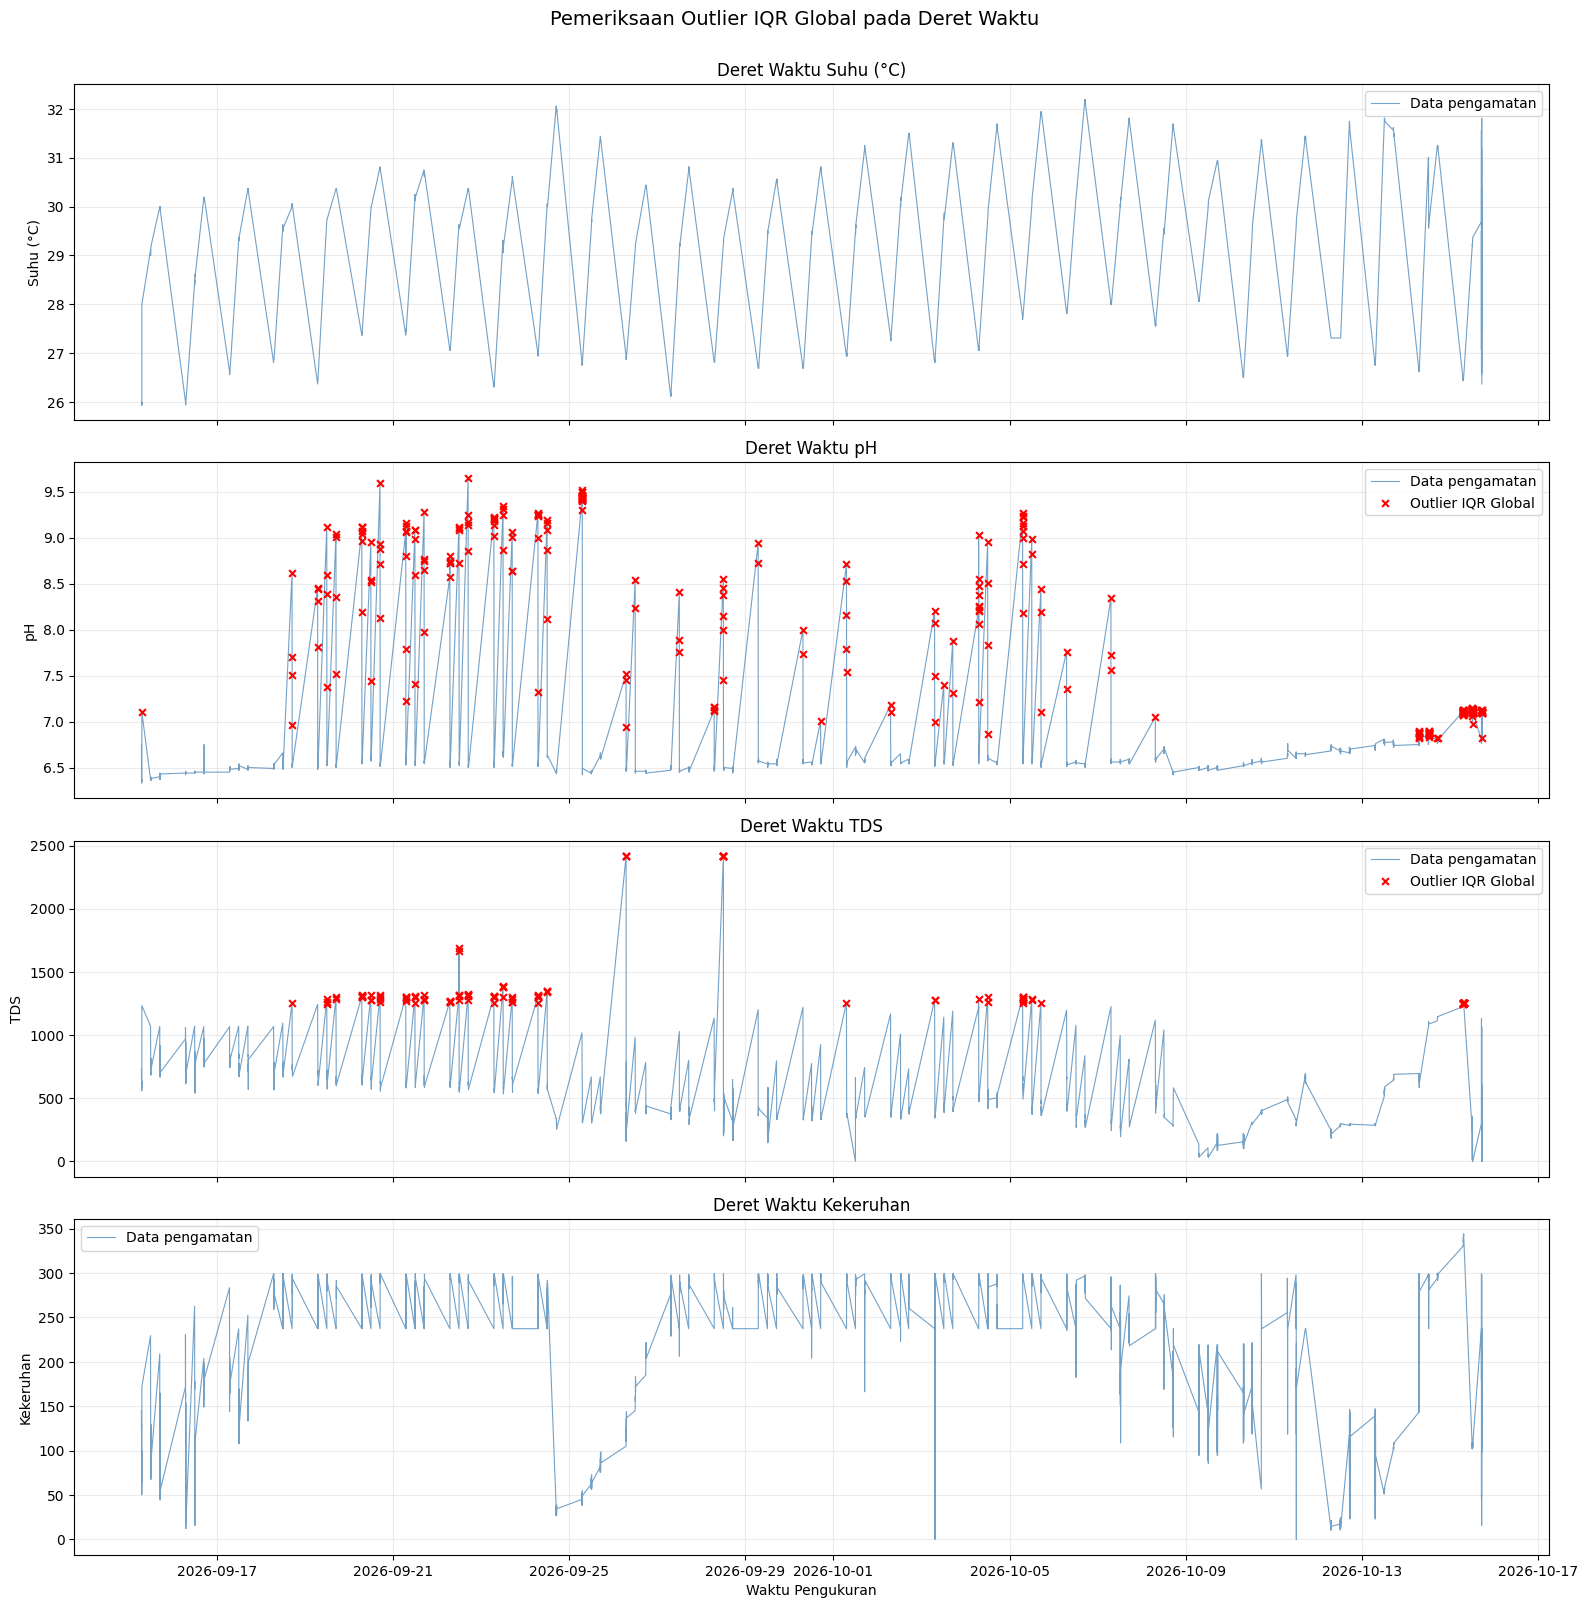

Grafik hanya menandai titik yang terdeteksi oleh IQR Global. Periksa pola dan konteks pengukurannya sebelum memutuskan apakah nilai tersebut merupakan gangguan sensor.


In [ ]:
# ============================================================
# 11B. VISUALISASI OUTLIER IQR GLOBAL PADA DERET WAKTU
# ============================================================
# Sel ini diletakkan setelah deteksi IQR Global (Sel 11)
# dan sebelum perbandingan IQR Global vs Sliding Window.
#
# Tujuan:
# 1. Melihat pola perubahan setiap parameter berdasarkan waktu.
# 2. Menandai titik yang terdeteksi sebagai outlier oleh IQR Global.
# 3. Membantu pemeriksaan apakah outlier berupa lonjakan sesaat
#    atau bagian dari perubahan kondisi yang berlangsung.
#
# Catatan: visualisasi ini tidak menghapus atau mengubah nilai data.

import matplotlib.pyplot as plt
import pandas as pd

fitur_plot = kolom_parameter
df_plot = df_cleaning.copy()
df_plot[kolom_waktu] = pd.to_datetime(df_plot[kolom_waktu], errors="coerce")
df_plot = df_plot.dropna(subset=[kolom_waktu]).sort_values(kolom_waktu)

# Ambil hanya outlier global untuk parameter yang sedang divisualisasikan.
df_outlier_plot = df_outlier.copy()
if not df_outlier_plot.empty:
    df_outlier_plot["Waktu Aktual"] = pd.to_datetime(
        df_outlier_plot["Waktu Aktual"], errors="coerce"
    )

fig, axes = plt.subplots(
    nrows=len(fitur_plot),
    ncols=1,
    figsize=(16, 4 * len(fitur_plot)),
    sharex=True
)

if len(fitur_plot) == 1:
    axes = [axes]

for ax, kolom in zip(axes, fitur_plot):
    # Seluruh pengamatan ditampilkan sebagai garis waktu.
    ax.plot(
        df_plot[kolom_waktu],
        df_plot[kolom],
        color="steelblue",
        linewidth=0.8,
        alpha=0.75,
        label="Data pengamatan"
    )

    # Titik outlier IQR Global ditandai dengan warna merah.
    if not df_outlier_plot.empty:
        titik_outlier = df_outlier_plot[
            df_outlier_plot["Parameter"] == kolom
        ].dropna(subset=["Waktu Aktual"])

        if not titik_outlier.empty:
            ax.scatter(
                titik_outlier["Waktu Aktual"],
                titik_outlier["Nilai"],
                color="red",
                s=24,
                marker="x",
                label="Outlier IQR Global",
                zorder=3
            )

    ax.set_title(f"Deret Waktu {kolom}")
    ax.set_ylabel(kolom)
    ax.grid(True, alpha=0.25)
    ax.legend(loc="best")

axes[-1].set_xlabel("Waktu Pengukuran")
fig.suptitle(
    "Pemeriksaan Outlier IQR Global pada Deret Waktu",
    fontsize=14,
    y=1.002
)
plt.tight_layout()
plt.show()

print(
    "Grafik hanya menandai titik yang terdeteksi oleh IQR Global. "
    "Periksa pola dan konteks pengukurannya sebelum memutuskan "
    "apakah nilai tersebut merupakan gangguan sensor."
)


RINGKASAN OUTLIER pH DAN TDS BERDASARKAN TANGGAL-SESI


,Parameter,Tanggal,Sesi,Jumlah Outlier
0,TDS,2026-09-18,17:00,1
1,TDS,2026-09-19,12:00,3
2,TDS,2026-09-19,17:00,2
3,TDS,2026-09-20,07:00,6
4,TDS,2026-09-20,12:00,3
...,...,...,...,...
69,pH,2026-10-14,12:00,15
70,pH,2026-10-14,17:00,2
71,pH,2026-10-15,07:00,30
72,pH,2026-10-15,12:00,30


DETAIL OUTLIER DAN 3 PENGUKURAN SEBELUM/SESUDAHNYA


,Tanggal,Sesi,Waktu Aktual,Parameter,Nilai,Status,Jarak dari Outlier (baris)
0,2026-09-18,17:00,2026-09-18 17:05:35.000,TDS,1252.80,OUTLIER IQR GLOBAL,0
1,2026-09-18,17:00,2026-09-18 17:06:03.000,TDS,1183.23,Data sekitar,1
2,2026-09-18,17:00,2026-09-18 17:06:34.000,TDS,1167.34,Data sekitar,2
3,2026-09-18,17:00,2026-09-18 17:07:03.000,TDS,1115.06,Data sekitar,3
4,2026-09-19,12:00,2026-09-19 12:00:42.623,TDS,1288.55,OUTLIER IQR GLOBAL,0
...,...,...,...,...,...,...,...
636,2026-10-15,17:00,2026-10-15 17:13:12.806,pH,6.78,Data sekitar,2
637,2026-10-15,17:00,2026-10-15 17:13:42.192,pH,6.78,Data sekitar,3
638,2026-10-15,17:00,2026-10-15 17:14:12.547,pH,7.09,OUTLIER IQR GLOBAL,0
639,2026-10-15,17:00,2026-10-15 17:14:42.324,pH,7.10,Data sekitar,1


Grafik pemeriksaan: 2026-09-18, sesi 17:00


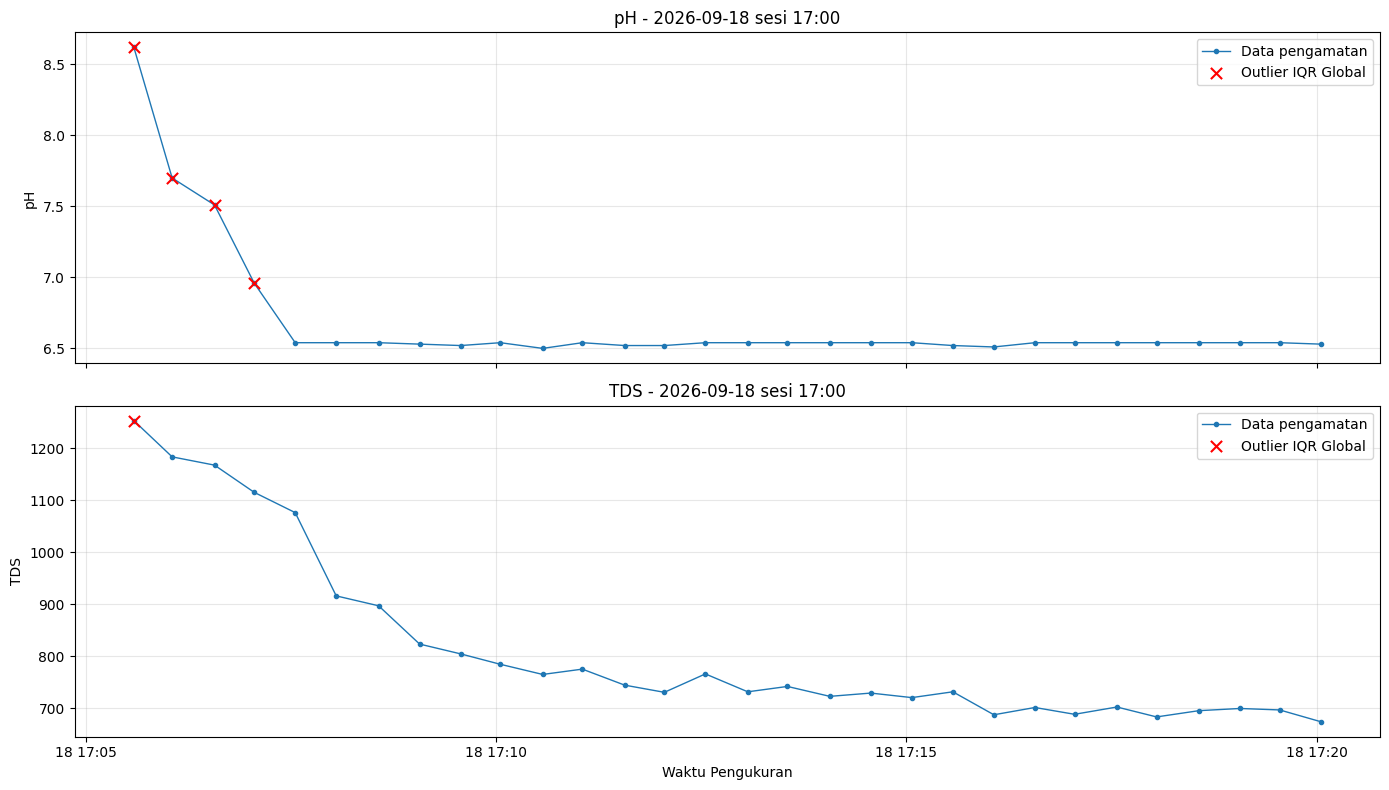

In [ ]:
# ============================================================
# 11C. PEMERIKSAAN KONTEKS OUTLIER pH DAN TDS (PERBAIKAN)
# ============================================================
# Tanggal dinormalisasi ke format YYYY-MM-DD agar tidak terjadi
# ketidakcocokan antara '2026-09-18' dan '2026-09-18 00:00:00'.
# Tidak ada nilai yang dihapus, diganti, atau diinterpolasi.

import pandas as pd
import matplotlib.pyplot as plt

parameter_diperiksa = ["pH", "TDS"]

df_konteks = df_cleaning.copy()
df_konteks[kolom_waktu] = pd.to_datetime(
    df_konteks[kolom_waktu], errors="coerce"
)
df_konteks["Tanggal_key"] = pd.to_datetime(
    df_konteks["Tanggal"], errors="coerce"
).dt.strftime("%Y-%m-%d")
df_konteks["Sesi_key"] = df_konteks["Sesi"].astype(str).str.slice(0, 5)
df_konteks = df_konteks.dropna(subset=[kolom_waktu, "Tanggal_key"]).copy()
df_konteks = df_konteks.sort_values(
    ["Tanggal_key", "Sesi_key", kolom_waktu]
)

df_flag = df_outlier[
    df_outlier["Parameter"].isin(parameter_diperiksa)
].copy()
df_flag["Waktu Aktual"] = pd.to_datetime(
    df_flag["Waktu Aktual"], errors="coerce"
)
df_flag["Tanggal_key"] = pd.to_datetime(
    df_flag["Tanggal"], errors="coerce"
).dt.strftime("%Y-%m-%d")
df_flag["Sesi_key"] = df_flag["Sesi"].astype(str).str.slice(0, 5)
df_flag = df_flag.dropna(subset=["Waktu Aktual", "Tanggal_key"]).copy()

# Ringkasan berdasarkan tanggal dan sesi yang sudah dinormalisasi.
if not df_flag.empty:
    ringkasan_konteks = (
        df_flag.groupby(
            ["Parameter", "Tanggal_key", "Sesi_key"], dropna=False
        ).size().reset_index(name="Jumlah Outlier")
        .rename(columns={"Tanggal_key": "Tanggal", "Sesi_key": "Sesi"})
        .sort_values(["Parameter", "Tanggal", "Sesi"])
        .reset_index(drop=True)
    )
else:
    ringkasan_konteks = pd.DataFrame(
        columns=["Parameter", "Tanggal", "Sesi", "Jumlah Outlier"]
    )

print("RINGKASAN OUTLIER pH DAN TDS BERDASARKAN TANGGAL-SESI")
display(ringkasan_konteks)

# Gunakan pasangan tanggal-sesi-waktu-parameter untuk menandai outlier.
kunci_outlier = set(
    zip(
        df_flag["Tanggal_key"],
        df_flag["Sesi_key"],
        df_flag["Waktu Aktual"],
        df_flag["Parameter"]
    )
)

baris_konteks = []
for (tanggal_key, sesi_key), grup in df_konteks.groupby(
    ["Tanggal_key", "Sesi_key"], sort=False
):
    grup = grup.sort_values(kolom_waktu).copy()

    for parameter in parameter_diperiksa:
        posisi_outlier = [
            pos for pos, (_, baris) in enumerate(grup.iterrows())
            if (
                tanggal_key,
                sesi_key,
                baris[kolom_waktu],
                parameter
            ) in kunci_outlier
        ]

        for posisi in posisi_outlier:
            awal = max(0, posisi - 3)
            akhir = min(len(grup), posisi + 4)

            for pos_konteks in range(awal, akhir):
                baris = grup.iloc[pos_konteks]
                status = (
                    "OUTLIER IQR GLOBAL"
                    if pos_konteks == posisi
                    else "Data sekitar"
                )
                baris_konteks.append({
                    "Tanggal": tanggal_key,
                    "Sesi": sesi_key,
                    "Waktu Aktual": baris[kolom_waktu],
                    "Parameter": parameter,
                    "Nilai": baris[parameter],
                    "Status": status,
                    "Jarak dari Outlier (baris)": pos_konteks - posisi
                })

df_konteks_outlier = pd.DataFrame(baris_konteks)
if not df_konteks_outlier.empty:
    df_konteks_outlier = (
        df_konteks_outlier
        .drop_duplicates(
            subset=["Tanggal", "Sesi", "Waktu Aktual", "Parameter"]
        )
        .sort_values(["Parameter", "Tanggal", "Sesi", "Waktu Aktual"])
        .reset_index(drop=True)
    )

print("DETAIL OUTLIER DAN 3 PENGUKURAN SEBELUM/SESUDAHNYA")
display(df_konteks_outlier)

# Pilih kombinasi tanggal-sesi pertama yang memiliki outlier.
if not ringkasan_konteks.empty:
    tanggal_pemeriksaan = ringkasan_konteks.iloc[0]["Tanggal"]
    sesi_pemeriksaan = ringkasan_konteks.iloc[0]["Sesi"]

    # Untuk memilih tanggal/sesi lain, ubah dua nilai di bawah ini.
    # Contoh:
    # tanggal_pemeriksaan = "2026-09-20"
    # sesi_pemeriksaan = "17:00"

    grup_pilihan = df_konteks[
        (df_konteks["Tanggal_key"] == tanggal_pemeriksaan) &
        (df_konteks["Sesi_key"] == sesi_pemeriksaan)
    ].sort_values(kolom_waktu)

    outlier_pilihan = df_flag[
        (df_flag["Tanggal_key"] == tanggal_pemeriksaan) &
        (df_flag["Sesi_key"] == sesi_pemeriksaan)
    ]

    print(
        f"Grafik pemeriksaan: {tanggal_pemeriksaan}, "
        f"sesi {sesi_pemeriksaan}"
    )

    fig, axes = plt.subplots(
        nrows=len(parameter_diperiksa),
        ncols=1,
        figsize=(14, 8),
        sharex=True
    )

    for ax, parameter in zip(axes, parameter_diperiksa):
        ax.plot(
            grup_pilihan[kolom_waktu],
            grup_pilihan[parameter],
            marker="o",
            markersize=3,
            linewidth=1,
            label="Data pengamatan"
        )

        titik = outlier_pilihan[
            outlier_pilihan["Parameter"] == parameter
        ]

        if not titik.empty:
            ax.scatter(
                titik["Waktu Aktual"],
                titik["Nilai"],
                color="red",
                marker="x",
                s=65,
                label="Outlier IQR Global",
                zorder=3
            )

        ax.set_title(
            f"{parameter} - {tanggal_pemeriksaan} sesi {sesi_pemeriksaan}"
        )
        ax.set_ylabel(parameter)
        ax.grid(True, alpha=0.3)
        ax.legend()

    axes[-1].set_xlabel("Waktu Pengukuran")
    plt.tight_layout()
    plt.show()
else:
    print("Tidak ditemukan outlier IQR Global pada pH maupun TDS.")


PERBANDINGAN JUMLAH OUTLIER


,Parameter,Outlier IQR Global,Outlier IQR Window 12,Terdeteksi Keduanya,Hanya Global,Hanya Window 12
0,Suhu (°C),0,476,0,0,476
1,pH,280,516,126,154,390
2,TDS,114,492,30,84,462
3,Kekeruhan,0,378,0,0,378



DETAIL OUTLIER - IQR GLOBAL


,Index,Tanggal,Sesi,Waktu Aktual,Parameter,Nilai,Batas Bawah Global,Batas Atas Global
0,512,2026-09-20,17:00,2026-09-20 17:01:39.006,pH,8.88,6.330,6.810
1,513,2026-09-20,17:00,2026-09-20 17:02:08.882,pH,8.71,6.330,6.810
2,514,2026-09-20,17:00,2026-09-20 17:02:39.049,pH,8.13,6.330,6.810
3,2070,2026-10-08,07:00,2026-10-08 07:22:11.101,pH,7.05,6.330,6.810
4,540,2026-09-21,07:00,2026-09-21 07:00:46.248,pH,9.06,6.330,6.810
...,...,...,...,...,...,...,...,...
389,481,2026-09-20,12:00,2026-09-20 12:02:33.250,TDS,1277.07,-172.465,1245.495
390,482,2026-09-20,12:00,2026-09-20 12:03:03.602,TDS,1276.26,-172.465,1245.495
391,992,2026-09-26,07:00,2026-09-26 07:04:34.593,TDS,2418.89,-172.465,1245.495
392,510,2026-09-20,17:00,2026-09-20 17:00:39.328,TDS,1317.65,-172.465,1245.495



DETAIL OUTLIER - IQR SLIDING WINDOW 12 TITIK


,Index,Tanggal,Sesi,Waktu Aktual,Parameter,Nilai,Batas Bawah Window,Batas Atas Window,Window Mulai,Window Selesai
0,26,2026-09-15,07:00,2026-09-15 07:14:57.536,Suhu (°C),26.00,25.94000,25.94000,2026-09-15 07:09:27.193,2026-09-15 07:14:57.536
1,26,2026-09-15,07:00,2026-09-15 07:14:57.536,Suhu (°C),26.00,25.94000,25.94000,2026-09-15 07:09:57.352,2026-09-15 07:15:27.440
2,26,2026-09-15,07:00,2026-09-15 07:14:57.536,Suhu (°C),26.00,25.94000,25.94000,2026-09-15 07:10:28.052,2026-09-15 07:15:57.331
3,26,2026-09-15,07:00,2026-09-15 07:14:57.536,Suhu (°C),26.00,25.94000,25.94000,2026-09-15 07:10:57.456,2026-09-15 07:16:27.684
4,29,2026-09-15,07:00,2026-09-15 07:16:27.684,Suhu (°C),28.00,25.94000,25.94000,2026-09-15 07:10:57.456,2026-09-15 07:16:27.684
...,...,...,...,...,...,...,...,...,...,...
5323,2778,2026-10-15,17:00,2026-10-15 17:09:42.605,Kekeruhan,15.62,58.98125,363.27125,2026-10-15 17:07:12.692,2026-10-15 17:12:42.473
5324,2778,2026-10-15,17:00,2026-10-15 17:09:42.605,Kekeruhan,15.62,56.25625,364.90625,2026-10-15 17:08:42.783,2026-10-15 17:14:12.547
5325,2778,2026-10-15,17:00,2026-10-15 17:09:42.605,Kekeruhan,15.62,124.72500,323.82500,2026-10-15 17:09:12.264,2026-10-15 17:14:42.324
5326,2785,2026-10-15,17:00,2026-10-15 17:13:12.806,Kekeruhan,103.10,124.72500,323.82500,2026-10-15 17:09:12.264,2026-10-15 17:14:42.324


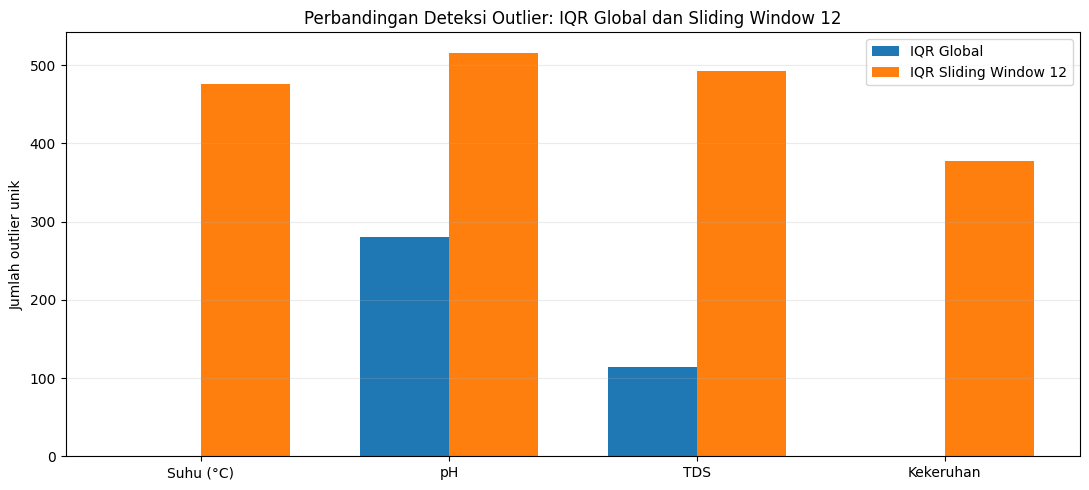


CATATAN ANALISIS: hasil ini merupakan perbandingan deteksi saja. Belum ada nilai outlier yang dihapus, dicapping, atau diinterpolasi. Periksa detail waktu dan konteks pengukuran sebelum menetapkan nilai mana yang benar-benar merupakan gangguan sensor.


In [ ]:
# ============================================================
# 11A. MEMBANDINGKAN DETEKSI OUTLIER:
# IQR KESELURUHAN vs IQR SLIDING WINDOW 12 TITIK
# ============================================================

# Catatan:
# - Sel ini hanya MEMERIKSA dan MEMBANDINGKAN deteksi outlier.
# - Belum mengubah/mengganti nilai pada df_cleaning.
# - Sliding window dihitung terpisah untuk setiap Tanggal-Sesi.
# - Window = 12 titik, bergeser 1 titik (stride=1).
# - IQR dihitung dari 12 nilai dalam setiap window.
# - Untuk mencegah satu titik dihitung berkali-kali, hasil window
#   digabungkan berdasarkan indeks data asli (union/unik).

ukuran_window = 12
kelompok_sesi = ["Tanggal", "Sesi"]

# Data kerja diurutkan berdasarkan waktu aktual dalam setiap sesi.
df_iqr_uji = df_cleaning.sort_values(
    kelompok_sesi + [kolom_waktu]
).copy()

hasil_perbandingan_iqr = []
detail_iqr_window = []
detail_iqr_global = []

for kolom in kolom_parameter:

    # --------------------------------------------------------
    # A. IQR GLOBAL (seluruh data untuk setiap parameter)
    # --------------------------------------------------------
    q1_global = df_iqr_uji[kolom].quantile(0.25)
    q3_global = df_iqr_uji[kolom].quantile(0.75)
    iqr_global = q3_global - q1_global
    bawah_global = q1_global - 1.5 * iqr_global
    atas_global = q3_global + 1.5 * iqr_global

    mask_global = (
        (df_iqr_uji[kolom] < bawah_global) |
        (df_iqr_uji[kolom] > atas_global)
    )

    indeks_global = set(df_iqr_uji.index[mask_global])

    for idx in indeks_global:
        detail_iqr_global.append({
            "Index": idx,
            "Tanggal": df_iqr_uji.at[idx, "Tanggal"],
            "Sesi": df_iqr_uji.at[idx, "Sesi"],
            "Waktu Aktual": df_iqr_uji.at[idx, kolom_waktu],
            "Parameter": kolom,
            "Nilai": df_iqr_uji.at[idx, kolom],
            "Batas Bawah Global": bawah_global,
            "Batas Atas Global": atas_global
        })

    # --------------------------------------------------------
    # B. IQR SLIDING WINDOW 12 TITIK, PER TANGGAL-SESI
    # --------------------------------------------------------
    indeks_window_outlier = set()

    for (tanggal, sesi), bagian in df_iqr_uji.groupby(
        kelompok_sesi, sort=False, dropna=False
    ):
        bagian = bagian.sort_values(kolom_waktu)
        nilai = bagian[kolom].astype(float)

        if len(bagian) < ukuran_window:
            continue

        # Window bergeser satu baris setiap iterasi.
        for posisi_awal in range(len(bagian) - ukuran_window + 1):
            window = bagian.iloc[
                posisi_awal:posisi_awal + ukuran_window
            ]

            nilai_window = window[kolom].dropna()

            # Jika ada nilai kosong, kuartil dihitung dari nilai
            # yang tersedia; jumlah nilai valid dicatat untuk audit.
            if len(nilai_window) < ukuran_window:
                continue

            q1_window = nilai_window.quantile(0.25)
            q3_window = nilai_window.quantile(0.75)
            iqr_window = q3_window - q1_window
            bawah_window = q1_window - 1.5 * iqr_window
            atas_window = q3_window + 1.5 * iqr_window

            mask_window = (
                (window[kolom] < bawah_window) |
                (window[kolom] > atas_window)
            )

            for idx in window.index[mask_window]:
                indeks_window_outlier.add(idx)
                detail_iqr_window.append({
                    "Index": idx,
                    "Tanggal": tanggal,
                    "Sesi": sesi,
                    "Waktu Aktual": df_iqr_uji.at[idx, kolom_waktu],
                    "Parameter": kolom,
                    "Nilai": df_iqr_uji.at[idx, kolom],
                    "Batas Bawah Window": bawah_window,
                    "Batas Atas Window": atas_window,
                    "Window Mulai": window[kolom_waktu].iloc[0],
                    "Window Selesai": window[kolom_waktu].iloc[-1]
                })

    # --------------------------------------------------------
    # C. RINGKASAN PERBANDINGAN
    # --------------------------------------------------------
    irisan = indeks_global.intersection(indeks_window_outlier)
    hanya_global = indeks_global - indeks_window_outlier
    hanya_window = indeks_window_outlier - indeks_global

    hasil_perbandingan_iqr.append({
        "Parameter": kolom,
        "Outlier IQR Global": len(indeks_global),
        "Outlier IQR Window 12": len(indeks_window_outlier),
        "Terdeteksi Keduanya": len(irisan),
        "Hanya Global": len(hanya_global),
        "Hanya Window 12": len(hanya_window)
    })

df_perbandingan_iqr = pd.DataFrame(hasil_perbandingan_iqr)
df_detail_iqr_global = pd.DataFrame(detail_iqr_global)
df_detail_iqr_window = pd.DataFrame(detail_iqr_window)

print("PERBANDINGAN JUMLAH OUTLIER")
display(df_perbandingan_iqr)

print("\nDETAIL OUTLIER - IQR GLOBAL")
display(df_detail_iqr_global)

print("\nDETAIL OUTLIER - IQR SLIDING WINDOW 12 TITIK")
display(df_detail_iqr_window)

# ------------------------------------------------------------
# D. VISUALISASI PERBANDINGAN JUMLAH OUTLIER
# ------------------------------------------------------------
import matplotlib.pyplot as plt
import numpy as np

posisi = np.arange(len(kolom_parameter))
lebar = 0.36

fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(
    posisi - lebar/2,
    df_perbandingan_iqr["Outlier IQR Global"],
    lebar,
    label="IQR Global"
)
ax.bar(
    posisi + lebar/2,
    df_perbandingan_iqr["Outlier IQR Window 12"],
    lebar,
    label="IQR Sliding Window 12"
)

ax.set_xticks(posisi)
ax.set_xticklabels(kolom_parameter)
ax.set_ylabel("Jumlah outlier unik")
ax.set_title("Perbandingan Deteksi Outlier: IQR Global dan Sliding Window 12")
ax.legend()
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

print(
    "\nCATATAN ANALISIS: hasil ini merupakan perbandingan deteksi saja. "
    "Belum ada nilai outlier yang dihapus, dicapping, atau diinterpolasi. "
    "Periksa detail waktu dan konteks pengukuran sebelum menetapkan "
    "nilai mana yang benar-benar merupakan gangguan sensor."
)


In [ ]:
# ============================================================
# 11A.1 MENAMPILKAN TABEL PERBANDINGAN OUTLIER
# ============================================================

print("TABEL PERBANDINGAN DETEKSI OUTLIER")

display(
    df_perbandingan_iqr.style.format({
        "Outlier IQR Global": "{:,.0f}",
        "Outlier IQR Window 12": "{:,.0f}",
        "Terdeteksi Keduanya": "{:,.0f}",
        "Hanya Global": "{:,.0f}",
        "Hanya Window 12": "{:,.0f}"
    })
)

TABEL PERBANDINGAN DETEKSI OUTLIER


,Parameter,Outlier IQR Global,Outlier IQR Window 12,Terdeteksi Keduanya,Hanya Global,Hanya Window 12
0,Suhu (°C),0,476,0,0,476
1,pH,280,516,126,154,390
2,TDS,114,492,30,84,462
3,Kekeruhan,0,378,0,0,378


RINGKASAN AUDIT DAN PENANGANAN OUTLIER


,Parameter,Kategori Pemeriksaan,Status Penanganan,Jumlah
0,TDS,Kandidat berkelompok,"Kandidat berkelompok - dipertahankan, perlu ve...",87
1,TDS,Kandidat di batas sesi,"Kandidat di batas sesi - dipertahankan, perlu ...",26
2,TDS,Kandidat terisolasi,"Kandidat terisolasi - dipertahankan, perlu ver...",1
3,pH,Kandidat berkelompok,"Kandidat berkelompok - dipertahankan, perlu ve...",224
4,pH,Kandidat di batas sesi,"Kandidat di batas sesi - dipertahankan, perlu ...",48
5,pH,Kandidat terisolasi,"Kandidat terisolasi - dipertahankan, perlu ver...",8


LOG SELURUH KANDIDAT OUTLIER


,Index,Tanggal,Sesi,Waktu Aktual,Parameter,Nilai Asli,Nilai Hasil,Kategori Pemeriksaan,Status Penanganan,Alasan
0,29,2026-09-15,07:00,2026-09-15 07:16:27.684,pH,7.10,7.10,Kandidat di batas sesi,"Kandidat di batas sesi - dipertahankan, perlu ...",Tidak memiliki dua tetangga dalam sesi yang sama
1,330,2026-09-18,17:00,2026-09-18 17:05:35.000,pH,8.62,8.62,Kandidat di batas sesi,"Kandidat di batas sesi - dipertahankan, perlu ...",Tidak memiliki dua tetangga dalam sesi yang sama
2,331,2026-09-18,17:00,2026-09-18 17:06:03.000,pH,7.70,7.70,Kandidat berkelompok,"Kandidat berkelompok - dipertahankan, perlu ve...",Terdapat kandidat outlier berurutan di sekitarnya
3,332,2026-09-18,17:00,2026-09-18 17:06:34.000,pH,7.51,7.51,Kandidat berkelompok,"Kandidat berkelompok - dipertahankan, perlu ve...",Terdapat kandidat outlier berurutan di sekitarnya
4,333,2026-09-18,17:00,2026-09-18 17:07:03.000,pH,6.96,6.96,Kandidat berkelompok,"Kandidat berkelompok - dipertahankan, perlu ve...",Terdapat kandidat outlier berurutan di sekitarnya
...,...,...,...,...,...,...,...,...,...,...
389,2780,2026-10-15,17:00,2026-10-15 17:10:42.931,pH,7.09,7.09,Kandidat terisolasi,"Kandidat terisolasi - dipertahankan, perlu ver...",Terisolasi secara statistik; belum membuktikan...
390,2783,2026-10-15,17:00,2026-10-15 17:12:12.058,pH,7.10,7.10,Kandidat terisolasi,"Kandidat terisolasi - dipertahankan, perlu ver...",Terisolasi secara statistik; belum membuktikan...
391,2787,2026-10-15,17:00,2026-10-15 17:14:12.547,pH,7.09,7.09,Kandidat berkelompok,"Kandidat berkelompok - dipertahankan, perlu ve...",Terdapat kandidat outlier berurutan di sekitarnya
392,2788,2026-10-15,17:00,2026-10-15 17:14:42.324,pH,7.10,7.10,Kandidat berkelompok,"Kandidat berkelompok - dipertahankan, perlu ve...",Terdapat kandidat outlier berurutan di sekitarnya


Jumlah kandidat outlier pH/TDS: 394
Jumlah kandidat tercatat pada log: 394
Jumlah nilai yang benar-benar diinterpolasi: 0


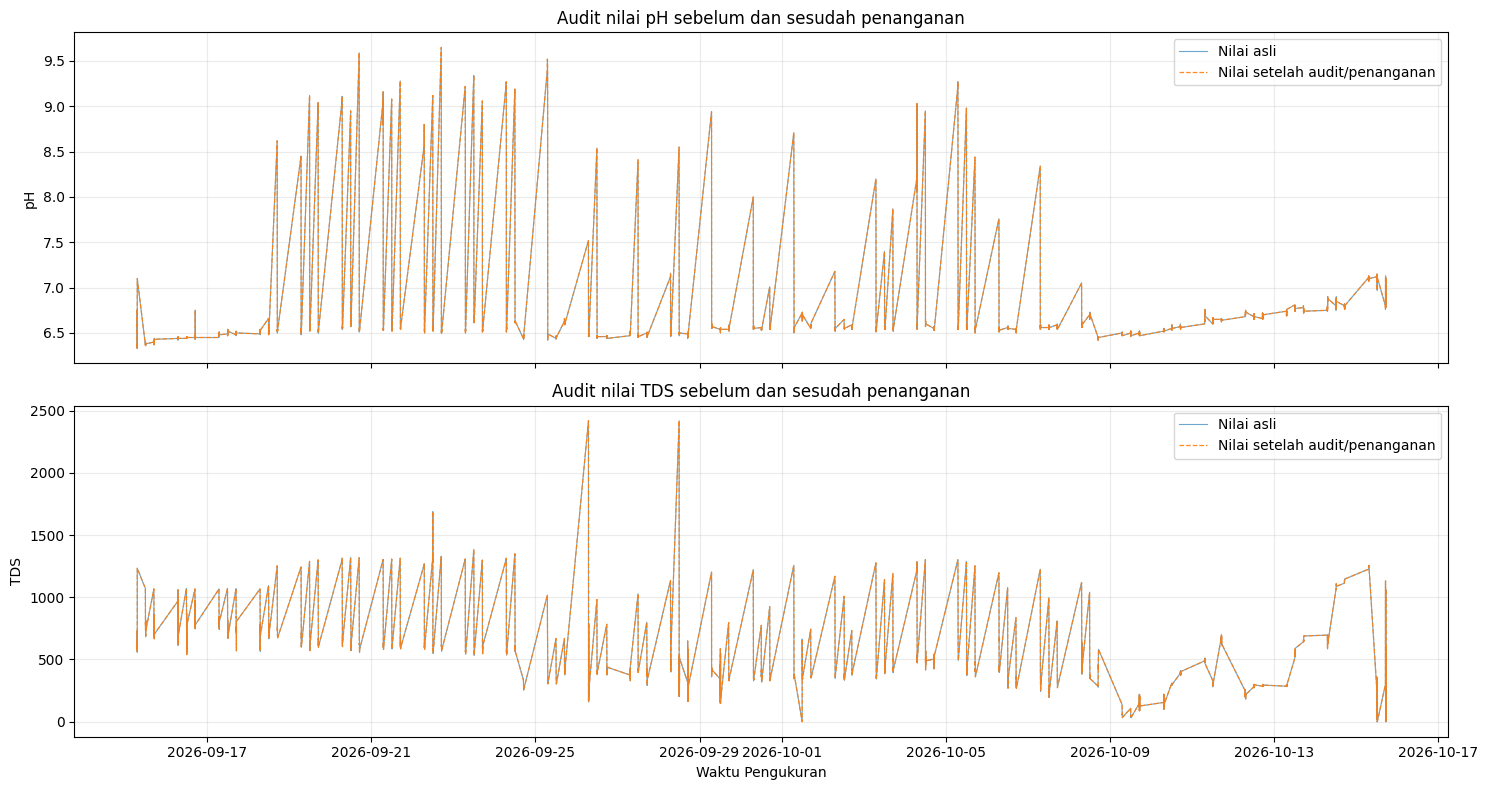

Dataset df_cleaning telah diperbarui. Secara default seluruh nilai outlier statistik dipertahankan. Interpolasi hanya terjadi setelah konfirmasi gangguan sensor pada daftar indeks di awal sel.


In [ ]:
# ============================================================
# 12. AUDIT DAN PENANGANAN OUTLIER IQR GLOBAL
# ============================================================
# Prinsip perbaikan:
# - IQR Global hanya menandai kandidat outlier statistik.
# - Kandidat terisolasi TIDAK otomatis diinterpolasi.
# - Interpolasi hanya dilakukan jika ada bukti independen bahwa
#   pengukuran merupakan gangguan/kesalahan sensor dan indexnya
#   dimasukkan secara eksplisit pada daftar konfirmasi di bawah.
# - Secara default daftar konfirmasi dikosongkan sehingga semua
#   nilai asli dipertahankan.
# - Proses tidak melewati batas tanggal dan sesi.
#
# Data asli tetap disimpan dan tidak ditimpa.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

parameter_ditangani = ["pH", "TDS"]

# Isi hanya setelah ada bukti bahwa nilai tertentu benar-benar
# merupakan kesalahan sensor. Format: (index_dataframe, "parameter")
# Contoh format saja: [(123, "pH"), (456, "TDS")]
# Jangan isi berdasarkan status outlier IQR saja.
indeks_gangguan_sensor_terkonfirmasi = []

df_hasil_penanganan = df_cleaning.copy()
df_hasil_penanganan[kolom_waktu] = pd.to_datetime(
    df_hasil_penanganan[kolom_waktu], errors="coerce"
)

if not df_hasil_penanganan.index.is_unique:
    raise ValueError(
        "Indeks df_cleaning tidak unik. Pastikan indeks unik sebelum "
        "melakukan pencocokan kandidat outlier."
    )

# Simpan nilai asli, nilai hasil, dan status audit.
for parameter in parameter_ditangani:
    df_hasil_penanganan[f"{parameter}_Asli"] = df_hasil_penanganan[parameter]
    df_hasil_penanganan[f"{parameter}_Hasil"] = df_hasil_penanganan[parameter]
    df_hasil_penanganan[f"{parameter}_Status"] = "Bukan kandidat outlier"

indeks_outlier_global = {
    parameter: set(
        df_outlier.loc[
            df_outlier["Parameter"] == parameter, "Index"
        ].tolist()
    )
    for parameter in parameter_ditangani
}

# Validasi daftar konfirmasi: hanya pasangan index-parameter yang
# memang tercatat sebagai kandidat IQR Global yang boleh diproses.
konfirmasi_valid = set()
for idx, parameter in indeks_gangguan_sensor_terkonfirmasi:
    if parameter not in parameter_ditangani:
        raise ValueError(f"Parameter konfirmasi tidak dikenal: {parameter}")
    if idx not in indeks_outlier_global[parameter]:
        raise ValueError(
            f"Index {idx} pada parameter {parameter} bukan kandidat "
            "outlier IQR Global."
        )
    konfirmasi_valid.add((idx, parameter))

log_penanganan = []

for (tanggal, sesi), grup in df_hasil_penanganan.groupby(
    ["Tanggal", "Sesi"], sort=False
):
    grup = grup.sort_values(kolom_waktu)
    indeks_urut = list(grup.index)

    for parameter in parameter_ditangani:
        daftar_outlier = indeks_outlier_global[parameter]

        for posisi, idx in enumerate(indeks_urut):
            if idx not in daftar_outlier:
                continue

            nilai_asli = df_hasil_penanganan.at[idx, parameter]
            waktu_tengah = df_hasil_penanganan.at[idx, kolom_waktu]

            # Klasifikasi awal berdasarkan posisi dan tetangga.
            if posisi == 0 or posisi == len(indeks_urut) - 1:
                kategori = "Kandidat di batas sesi"
                alasan = "Tidak memiliki dua tetangga dalam sesi yang sama"
            else:
                idx_sebelum = indeks_urut[posisi - 1]
                idx_sesudah = indeks_urut[posisi + 1]

                tetangga_outlier = (
                    idx_sebelum in daftar_outlier or
                    idx_sesudah in daftar_outlier
                )

                if tetangga_outlier:
                    kategori = "Kandidat berkelompok"
                    alasan = "Terdapat kandidat outlier berurutan di sekitarnya"
                else:
                    kategori = "Kandidat terisolasi"
                    alasan = (
                        "Terisolasi secara statistik; belum membuktikan "
                        "adanya kesalahan sensor"
                    )

            status = kategori + " - dipertahankan, perlu verifikasi"
            nilai_hasil = nilai_asli

            # Interpolasi hanya jika ada konfirmasi gangguan sensor eksplisit.
            if (idx, parameter) in konfirmasi_valid:
                if posisi == 0 or posisi == len(indeks_urut) - 1:
                    status = "Terkonfirmasi tetapi tidak diinterpolasi"
                    alasan = (
                        "Berada di batas sesi; interpolasi tidak dilakukan "
                        "karena tidak tersedia dua tetangga"
                    )
                else:
                    idx_sebelum = indeks_urut[posisi - 1]
                    idx_sesudah = indeks_urut[posisi + 1]

                    nilai_sebelum = df_hasil_penanganan.at[idx_sebelum, parameter]
                    nilai_sesudah = df_hasil_penanganan.at[idx_sesudah, parameter]
                    waktu_sebelum = df_hasil_penanganan.at[idx_sebelum, kolom_waktu]
                    waktu_sesudah = df_hasil_penanganan.at[idx_sesudah, kolom_waktu]

                    # Jangan interpolasi jika tetangga juga merupakan
                    # kandidat outlier atau data/waktu tidak valid.
                    if (
                        idx_sebelum in daftar_outlier or
                        idx_sesudah in daftar_outlier or
                        pd.isna(nilai_sebelum) or
                        pd.isna(nilai_sesudah) or
                        pd.isna(waktu_sebelum) or
                        pd.isna(waktu_tengah) or
                        pd.isna(waktu_sesudah)
                    ):
                        status = "Terkonfirmasi tetapi tidak diinterpolasi"
                        alasan = (
                            "Tetangga tidak memenuhi syarat interpolasi "
                            "atau termasuk kandidat outlier"
                        )
                    else:
                        total_detik = (waktu_sesudah - waktu_sebelum).total_seconds()
                        kiri_detik = (waktu_tengah - waktu_sebelum).total_seconds()
                        kanan_detik = (waktu_sesudah - waktu_tengah).total_seconds()

                        # Batasi gap agar interpolasi tidak melintasi jeda
                        # waktu yang terlalu besar.
                        waktu_grup = grup[kolom_waktu].dropna().sort_values()
                        interval = waktu_grup.diff().dt.total_seconds().dropna()
                        interval = interval[interval > 0]
                        median_interval = (
                            float(interval.median()) if not interval.empty else np.nan
                        )

                        if (
                            pd.isna(median_interval) or
                            total_detik <= 0 or
                            kiri_detik <= 0 or
                            kanan_detik <= 0 or
                            kiri_detik > 2 * median_interval or
                            kanan_detik > 2 * median_interval
                        ):
                            status = "Terkonfirmasi tetapi tidak diinterpolasi"
                            alasan = "Jarak waktu tetangga tidak memenuhi syarat"
                        else:
                            proporsi = kiri_detik / total_detik
                            nilai_hasil = (
                                float(nilai_sebelum) +
                                proporsi * (float(nilai_sesudah) - float(nilai_sebelum))
                            )
                            status = "Gangguan sensor terkonfirmasi - diinterpolasi"
                            alasan = (
                                "Interpolasi linear berdasarkan dua tetangga "
                                "valid dalam tanggal dan sesi yang sama"
                            )

            df_hasil_penanganan.at[idx, f"{parameter}_Hasil"] = nilai_hasil
            df_hasil_penanganan.at[idx, f"{parameter}_Status"] = status

            log_penanganan.append({
                "Index": idx,
                "Tanggal": tanggal,
                "Sesi": sesi,
                "Waktu Aktual": waktu_tengah,
                "Parameter": parameter,
                "Nilai Asli": nilai_asli,
                "Nilai Hasil": nilai_hasil,
                "Kategori Pemeriksaan": kategori,
                "Status Penanganan": status,
                "Alasan": alasan
            })

df_log_penanganan = pd.DataFrame(log_penanganan)

if not df_log_penanganan.empty:
    ringkasan_penanganan = (
        df_log_penanganan.groupby(
            ["Parameter", "Kategori Pemeriksaan", "Status Penanganan"]
        )
        .size()
        .reset_index(name="Jumlah")
    )
else:
    ringkasan_penanganan = pd.DataFrame(
        columns=[
            "Parameter", "Kategori Pemeriksaan",
            "Status Penanganan", "Jumlah"
        ]
    )

print("RINGKASAN AUDIT DAN PENANGANAN OUTLIER")
display(ringkasan_penanganan)

print("LOG SELURUH KANDIDAT OUTLIER")
display(df_log_penanganan)

jumlah_kandidat = sum(len(v) for v in indeks_outlier_global.values())
jumlah_log = len(df_log_penanganan)
jumlah_interpolasi = (
    df_log_penanganan["Status Penanganan"].eq(
        "Gangguan sensor terkonfirmasi - diinterpolasi"
    ).sum()
    if not df_log_penanganan.empty else 0
)

print(f"Jumlah kandidat outlier pH/TDS: {jumlah_kandidat}")
print(f"Jumlah kandidat tercatat pada log: {jumlah_log}")
print(f"Jumlah nilai yang benar-benar diinterpolasi: {jumlah_interpolasi}")

# Terapkan hanya nilai yang telah dikonfirmasi dan berhasil diinterpolasi.
for parameter in parameter_ditangani:
    df_hasil_penanganan[parameter] = df_hasil_penanganan[
        f"{parameter}_Hasil"
    ]

# Perbarui dataset utama untuk tahapan berikutnya.
df_cleaning = df_hasil_penanganan.copy()

# Grafik ringkas sebelum-sesudah. Jika tidak ada nilai terkonfirmasi,
# kedua garis akan berimpit karena data memang dipertahankan.
fig, axes = plt.subplots(
    nrows=len(parameter_ditangani),
    ncols=1,
    figsize=(15, 8),
    sharex=True
)

for ax, parameter in zip(axes, parameter_ditangani):
    data_grafik = df_hasil_penanganan.sort_values(kolom_waktu)

    ax.plot(
        data_grafik[kolom_waktu],
        data_grafik[f"{parameter}_Asli"],
        linewidth=0.8,
        alpha=0.65,
        label="Nilai asli"
    )
    ax.plot(
        data_grafik[kolom_waktu],
        data_grafik[f"{parameter}_Hasil"],
        linewidth=0.9,
        alpha=0.9,
        linestyle="--",
        label="Nilai setelah audit/penanganan"
    )

    hasil_interpolasi = df_log_penanganan[
        (df_log_penanganan["Parameter"] == parameter) &
        (df_log_penanganan["Status Penanganan"] ==
         "Gangguan sensor terkonfirmasi - diinterpolasi")
    ] if not df_log_penanganan.empty else pd.DataFrame()

    if not hasil_interpolasi.empty:
        ax.scatter(
            hasil_interpolasi["Waktu Aktual"],
            hasil_interpolasi["Nilai Hasil"],
            color="red",
            marker="x",
            s=40,
            label="Titik terkonfirmasi dan diinterpolasi",
            zorder=3
        )

    ax.set_title(f"Audit nilai {parameter} sebelum dan sesudah penanganan")
    ax.set_ylabel(parameter)
    ax.grid(True, alpha=0.25)
    ax.legend()

axes[-1].set_xlabel("Waktu Pengukuran")
plt.tight_layout()
plt.show()

print(
    "Dataset df_cleaning telah diperbarui. Secara default seluruh nilai "
    "outlier statistik dipertahankan. Interpolasi hanya terjadi setelah "
    "konfirmasi gangguan sensor pada daftar indeks di awal sel."
)


In [ ]:
# ============================================================
# 12A. MENAMPILKAN TABEL RINGKASAN AUDIT OUTLIER
# ============================================================

print("TABEL RINGKASAN AUDIT DAN PENANGANAN OUTLIER")

display(
    ringkasan_penanganan.pivot_table(
        index=["Parameter", "Kategori Pemeriksaan"],
        columns="Status Penanganan",
        values="Jumlah",
        aggfunc="sum",
        fill_value=0
    ).reset_index()
)

TABEL RINGKASAN AUDIT DAN PENANGANAN OUTLIER


Status Penanganan,Parameter,Kategori Pemeriksaan,"Kandidat berkelompok - dipertahankan, perlu verifikasi","Kandidat di batas sesi - dipertahankan, perlu verifikasi","Kandidat terisolasi - dipertahankan, perlu verifikasi"
0,TDS,Kandidat berkelompok,87,0,0
1,TDS,Kandidat di batas sesi,0,26,0
2,TDS,Kandidat terisolasi,0,0,1
3,pH,Kandidat berkelompok,224,0,0
4,pH,Kandidat di batas sesi,0,48,0
5,pH,Kandidat terisolasi,0,0,8


In [ ]:
# ============================================================
# 12. RINGKASAN DAN MENYIMPAN HASIL DATA CLEANING
# ============================================================

ringkasan = pd.DataFrame({
    "Tahapan": [
        "Jumlah data awal",
        "Duplikat identik dihapus",
        "Tanggal tidak terbaca",
        "Waktu Aktual tidak terbaca",
        "Sesi tidak dikenal",
        "Baris semua parameter kosong",
        "Baris dengan parameter kosong sebelum imputasi",
        "Jumlah data akhir"
    ],
    "Jumlah": [
        jumlah_data_awal,
        jumlah_duplikat,
        len(df_tanggal_invalid),
        len(df_waktu_invalid),
        len(df_sesi_tidak_dikenal),
        len(df_baris_kosong),
        jumlah_missing_tersisa,
        len(df_cleaning)
    ]
})

print("RINGKASAN DATA CLEANING")
display(ringkasan)
print("\nJumlah data akhir:", len(df_cleaning))
print("Jumlah kolom:", len(df_cleaning.columns))
print("Jumlah duplikat identik:", df_cleaning.duplicated().sum())

# df_cleaning pada tahap ini sudah mencakup hasil imputasi dan penanganan outlier.
df_hasil_cleaning = df_cleaning.drop(
    columns=["_sesi"], errors="ignore"
).copy()

nama_file = "Hasil_Data_Cleaning_Lele.xlsx"

if "df_ringkasan_sesi" not in globals():
    raise NameError("df_ringkasan_sesi belum dibuat. Jalankan kembali sel validasi jumlah pembacaan dan durasi sesi (bagian 7) sebelum menyimpan.")

with pd.ExcelWriter(nama_file, engine="openpyxl") as writer:
    df_hasil_cleaning.to_excel(writer, sheet_name="Data_Cleaning", index=False)
    ringkasan.to_excel(writer, sheet_name="Ringkasan", index=False)
    df_hasil_iqr.to_excel(writer, sheet_name="Hasil_IQR", index=False)
    df_outlier.to_excel(writer, sheet_name="Detail_Outlier", index=False)
    df_ringkasan_sesi.to_excel(writer, sheet_name="Jumlah_per_Sesi", index=False)
    df_sesi_tidak_dikenal.to_excel(writer, sheet_name="Sesi_Tidak_Dikenal", index=False)
    df_missing_tersisa.to_excel(writer, sheet_name="Missing_Tersisa", index=False)
    df_log_penanganan.to_excel(writer, sheet_name="Log_Penanganan_Outlier", index=False)

print(f"File berhasil disimpan: {nama_file}")

# Untuk Google Colab, aktifkan baris berikut jika ingin mengunduh file:
from google.colab import files
files.download(nama_file)

RINGKASAN DATA CLEANING


,Tahapan,Jumlah
0,Jumlah data awal,2790
1,Duplikat identik dihapus,0
2,Tanggal tidak terbaca,0
3,Waktu Aktual tidak terbaca,0
4,Sesi tidak dikenal,0
5,Baris semua parameter kosong,4
6,Baris dengan parameter kosong sebelum imputasi,24
7,Jumlah data akhir,2786



Jumlah data akhir: 2786
Jumlah kolom: 13
Jumlah duplikat identik: 0
File berhasil disimpan: Hasil_Data_Cleaning_Lele.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Analisis Korelasi Antarparameter Kualitas Air

Jumlah data yang digunakan: 2786

Jumlah missing value per parameter:


,Missing Value
Suhu (°C),0
pH,0
TDS,0
Kekeruhan,0



Matriks Korelasi Pearson:


,Suhu (°C),pH,TDS,Kekeruhan
Suhu (°C),1.000,-0.124,-0.122,0.006
pH,-0.124,1.000,0.519,-0.046
TDS,-0.122,0.519,1.000,0.179
Kekeruhan,0.006,-0.046,0.179,1.000



Matriks Korelasi Spearman:


,Suhu (°C),pH,TDS,Kekeruhan
Suhu (°C),1.000,0.004,-0.118,-0.023
pH,0.004,1.000,0.146,0.098
TDS,-0.118,0.146,1.000,0.134
Kekeruhan,-0.023,0.098,0.134,1.000



Hasil korelasi dan uji signifikansi:


,Pasangan Parameter,Pearson (r),p-value Pearson,Spearman (rho),p-value Spearman,Jumlah Pasangan Data
0,Suhu (°C) - pH,-0.1243,0.0000,0.0043,0.8216,2786
1,Suhu (°C) - TDS,-0.1216,0.0000,-0.1184,0.0000,2786
2,Suhu (°C) - Kekeruhan,0.0057,0.7655,-0.0226,0.2340,2786
3,pH - TDS,0.5188,0.0000,0.1458,0.0000,2786
4,pH - Kekeruhan,-0.0458,0.0155,0.0975,0.0000,2786
5,TDS - Kekeruhan,0.1786,0.0000,0.1343,0.0000,2786


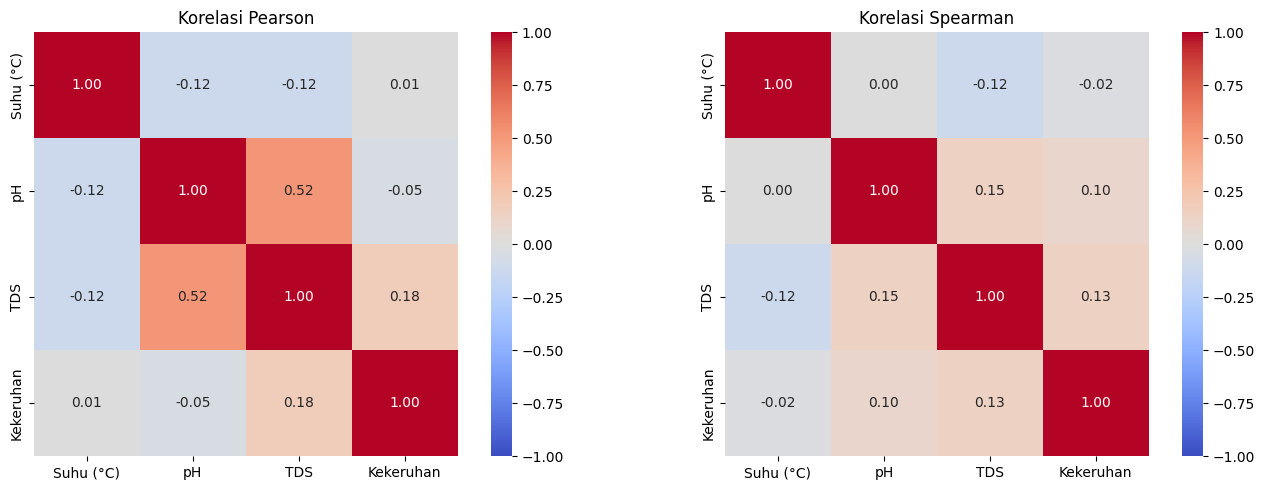


Ringkasan interpretasi korelasi:


,Pasangan Parameter,Pearson (r),p-value Pearson,Spearman (rho),p-value Spearman,Jumlah Pasangan Data,Interpretasi Pearson,Interpretasi Spearman
0,Suhu (°C) - pH,-0.124286,4.619598e-11,0.004273,8.216486e-01,2786,Sangat lemah,Sangat lemah
1,Suhu (°C) - TDS,-0.121564,1.214956e-10,-0.118412,3.626078e-10,2786,Sangat lemah,Sangat lemah
2,Suhu (°C) - Kekeruhan,0.005652,7.655469e-01,-0.022557,2.339606e-01,2786,Sangat lemah,Sangat lemah
3,pH - TDS,0.518774,8.553952e-192,0.145841,1.027614e-14,2786,Sedang,Sangat lemah
4,pH - Kekeruhan,-0.045846,1.551731e-02,0.097543,2.488461e-07,2786,Sangat lemah,Sangat lemah
5,TDS - Kekeruhan,0.178631,2.081004e-21,0.134282,1.104393e-12,2786,Sangat lemah,Sangat lemah


In [ ]:
# ============================================================
# 13. ANALISIS KORELASI ANTARPARAMETER KUALITAS AIR
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, spearmanr

# Empat fitur yang digunakan dalam penelitian
fitur_korelasi = ["Suhu (°C)", "pH", "TDS", "Kekeruhan"]

# Pastikan seluruh fitur bertipe numerik
data_korelasi = df_cleaning[fitur_korelasi].apply(
    pd.to_numeric, errors="coerce"
)

print("Jumlah data yang digunakan:", len(data_korelasi))
print("\nJumlah missing value per parameter:")
display(data_korelasi.isna().sum().rename("Missing Value").to_frame())

# 1. Matriks korelasi Pearson
korelasi_pearson = data_korelasi.corr(method="pearson")
print("\nMatriks Korelasi Pearson:")
display(korelasi_pearson.round(3))

# 2. Matriks korelasi Spearman
korelasi_spearman = data_korelasi.corr(method="spearman")
print("\nMatriks Korelasi Spearman:")
display(korelasi_spearman.round(3))

# 3. Nilai signifikansi (p-value) untuk setiap pasangan fitur
hasil_signifikansi = []

for i in range(len(fitur_korelasi)):
    for j in range(i + 1, len(fitur_korelasi)):
        fitur_1 = fitur_korelasi[i]
        fitur_2 = fitur_korelasi[j]

        pasangan = data_korelasi[[fitur_1, fitur_2]].dropna()

        if len(pasangan) >= 3:
            r_pearson, p_pearson = pearsonr(
                pasangan[fitur_1], pasangan[fitur_2]
            )
            r_spearman, p_spearman = spearmanr(
                pasangan[fitur_1], pasangan[fitur_2]
            )
        else:
            r_pearson = p_pearson = np.nan
            r_spearman = p_spearman = np.nan

        hasil_signifikansi.append({
            "Pasangan Parameter": f"{fitur_1} - {fitur_2}",
            "Pearson (r)": r_pearson,
            "p-value Pearson": p_pearson,
            "Spearman (rho)": r_spearman,
            "p-value Spearman": p_spearman,
            "Jumlah Pasangan Data": len(pasangan)
        })

df_signifikansi_korelasi = pd.DataFrame(hasil_signifikansi)

print("\nHasil korelasi dan uji signifikansi:")
display(df_signifikansi_korelasi.round(4))

# 4. Visualisasi heatmap Pearson dan Spearman
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(
    korelasi_pearson,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    ax=axes[0]
)
axes[0].set_title("Korelasi Pearson")

sns.heatmap(
    korelasi_spearman,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    ax=axes[1]
)
axes[1].set_title("Korelasi Spearman")

plt.tight_layout()
plt.show()

# 5. Ringkasan interpretasi kekuatan korelasi (berdasarkan nilai absolut)
def interpretasi_korelasi(nilai):
    if pd.isna(nilai):
        return "Tidak dapat dihitung"
    nilai = abs(nilai)
    if nilai < 0.20:
        return "Sangat lemah"
    elif nilai < 0.40:
        return "Lemah"
    elif nilai < 0.60:
        return "Sedang"
    elif nilai < 0.80:
        return "Kuat"
    else:
        return "Sangat kuat"

ringkasan_korelasi = df_signifikansi_korelasi.copy()
ringkasan_korelasi["Interpretasi Pearson"] = (
    ringkasan_korelasi["Pearson (r)"].apply(interpretasi_korelasi)
)
ringkasan_korelasi["Interpretasi Spearman"] = (
    ringkasan_korelasi["Spearman (rho)"].apply(interpretasi_korelasi)
)

print("\nRingkasan interpretasi korelasi:")
display(ringkasan_korelasi)

# Catatan:
# Korelasi dihitung menggunakan df_cleaning, yaitu data setelah
# penanganan missing value. Karena itu, hasilnya perlu ditafsirkan
# dengan mempertimbangkan bahwa sebagian nilai telah diimputasi.
# Korelasi yang tinggi tidak otomatis membuktikan bahwa KNN Imputation
# lebih baik; pemilihan metode imputasi tetap perlu diuji dengan
# menyembunyikan nilai valid dan membandingkan kesalahan imputasinya.


# Rule-Based Labeling

In [ ]:


# 6.1 Menyiapkan dataset

# Membuat salinan dataset hasil data cleaning
df_model = df_cleaning.copy()

# Menentukan empat parameter kualitas air
kolom_parameter = [
    "Suhu (°C)",
    "pH",
    "TDS",
    "Kekeruhan"
]

# Memeriksa ketersediaan kolom
kolom_tidak_ada = [
    kolom for kolom in kolom_parameter
    if kolom not in df_model.columns
]

if kolom_tidak_ada:
    raise ValueError(
        f"Kolom parameter tidak ditemukan: {kolom_tidak_ada}"
    )

# Memastikan parameter bertipe numerik
for kolom in kolom_parameter:
    df_model[kolom] = pd.to_numeric(
        df_model[kolom],
        errors="coerce"
    )

# Menampilkan kondisi data sebelum labeling
print("Jumlah data:", len(df_model))

print("\nMissing value pada setiap parameter:")
print(df_model[kolom_parameter].isna().sum())

print("\nContoh data yang akan diberi label:")
display(df_model[kolom_parameter].head(10))


Jumlah data: 2786

Missing value pada setiap parameter:
Suhu (°C)    0
pH           0
TDS          0
Kekeruhan    0
dtype: int64

Contoh data yang akan diberi label:


,Suhu (°C),pH,TDS,Kekeruhan
0,25.94,6.75,728.69,145.21
1,25.94,6.75,728.69,145.21
2,25.94,6.75,688.40,142.87
3,25.94,6.75,670.59,123.75
4,25.94,6.75,650.11,103.29
5,25.94,6.75,630.18,113.19
6,25.94,6.36,640.94,96.54
7,25.94,6.36,626.76,100.17
8,25.94,6.36,666.09,130.03
9,25.94,6.35,615.78,113.89


In [ ]:

# Menampilkan nama DataFrame yang tersedia di Google Colab
for nama, objek in globals().copy().items():
    if isinstance(objek, pd.DataFrame):
        print(nama, ":", objek.shape)


df : (2790, 7)
df_raw : (2790, 7)
df_cleaning : (2786, 13)
df_anomali : (0, 0)
df_sesi_tidak_dikenal : (0, 7)
df_tanggal_invalid : (0, 7)
df_waktu_invalid : (0, 7)
df_interval_waktu : (2790, 8)
df_validasi_sesi : (2790, 7)
bagian : (30, 7)
df_ringkasan_sesi : (93, 15)
duplikat_waktu_sesi : (0, 7)
df_interval_sesi : (2790, 8)
df_baris_kosong : (4, 7)
df_uji_imputasi : (2786, 7)
data_masked : (2786, 4)
df_perbandingan_imputasi : (4, 6)
df_audit_missing : (33, 12)
df_sebelum_imputasi : (2786, 7)
df_hasil_imputasi : (2786, 7)
data_final_knn : (2786, 4)
df_log_imputasi : (33, 7)
ringkasan_imputasi : (7, 4)
df_missing_tersisa : (0, 7)
df_hasil_iqr : (4, 7)
df_outlier : (394, 11)
df_plot : (2786, 7)
df_outlier_plot : (394, 11)
titik_outlier : (0, 11)
df_konteks : (2786, 9)
df_flag : (394, 13)
ringkasan_konteks : (74, 4)
grup : (30, 13)
df_konteks_outlier : (641, 7)
grup_pilihan : (30, 9)
outlier_pilihan : (5, 13)
titik : (1, 13)
df_iqr_uji : (2786, 7)
window : (12, 7)
df_perbandingan_iqr : (4

In [ ]:
# ============================================================
# PEMERIKSAAN NILAI pH SEBELUM DAN SESUDAH DATA CLEANING
# ============================================================

print("=== DATA AWAL ===")
print("Jumlah baris:", len(df_raw))
print("Jumlah pH terisi:", df_raw["pH"].notna().sum())
print("Jumlah pH kosong:", df_raw["pH"].isna().sum())

print("\n=== DATA SETELAH PEMERIKSAAN JADWAL ===")
print("Jumlah baris:", len(df_cleaning))
print("Jumlah pH terisi:", df_cleaning["pH"].notna().sum())
print("Jumlah pH kosong:", df_cleaning["pH"].isna().sum())

kolom_tampil = ["Tanggal", "Sesi", "Waktu Aktual",
                "Suhu (°C)", "pH", "TDS", "Kekeruhan"]

print("\n=== CONTOH DATA AWAL ===")
display(df_raw[[c for c in kolom_tampil if c in df_raw.columns]].head(15))

print("\n=== CONTOH DATA DENGAN pH TERISI ===")
display(
    df_raw.loc[df_raw["pH"].notna(),
               [c for c in kolom_tampil if c in df_raw.columns]].head(15)
)

=== DATA AWAL ===
Jumlah baris: 2790
Jumlah pH terisi: 2775
Jumlah pH kosong: 15

=== DATA SETELAH PEMERIKSAAN JADWAL ===
Jumlah baris: 2786
Jumlah pH terisi: 2786
Jumlah pH kosong: 0

=== CONTOH DATA AWAL ===


,Tanggal,Sesi,Waktu Aktual,Suhu (°C),pH,TDS,Kekeruhan
0,2026-09-15,07:00,2026-09-15 07:01:57.000,25.94,"6,75",728.69,145.21
1,2026-09-15,07:00,2026-09-15 07:02:28.000,25.94,"6,75",728.69,145.21
2,2026-09-15,07:00,2026-09-15 07:02:57.004,25.94,"6,75",688.40,142.87
3,2026-09-15,07:00,2026-09-15 07:03:27.198,25.94,"6,75",670.59,123.75
4,2026-09-15,07:00,2026-09-15 07:03:57.493,25.94,"6,75",650.11,103.29
5,2026-09-15,07:00,2026-09-15 07:04:27.616,25.94,"6,75",630.18,113.19
6,2026-09-15,07:00,2026-09-15 07:04:58.100,25.94,"6,36",640.94,96.54
7,2026-09-15,07:00,2026-09-15 07:05:27.410,25.94,"6,36",626.76,100.17
8,2026-09-15,07:00,2026-09-15 07:05:58.085,25.94,"6,36",666.09,130.03
9,2026-09-15,07:00,2026-09-15 07:06:28.059,25.94,"6,35",615.78,113.89



=== CONTOH DATA DENGAN pH TERISI ===


,Tanggal,Sesi,Waktu Aktual,Suhu (°C),pH,TDS,Kekeruhan
0,2026-09-15,07:00,2026-09-15 07:01:57.000,25.94,"6,75",728.69,145.21
1,2026-09-15,07:00,2026-09-15 07:02:28.000,25.94,"6,75",728.69,145.21
2,2026-09-15,07:00,2026-09-15 07:02:57.004,25.94,"6,75",688.40,142.87
3,2026-09-15,07:00,2026-09-15 07:03:27.198,25.94,"6,75",670.59,123.75
4,2026-09-15,07:00,2026-09-15 07:03:57.493,25.94,"6,75",650.11,103.29
5,2026-09-15,07:00,2026-09-15 07:04:27.616,25.94,"6,75",630.18,113.19
6,2026-09-15,07:00,2026-09-15 07:04:58.100,25.94,"6,36",640.94,96.54
7,2026-09-15,07:00,2026-09-15 07:05:27.410,25.94,"6,36",626.76,100.17
8,2026-09-15,07:00,2026-09-15 07:05:58.085,25.94,"6,36",666.09,130.03
9,2026-09-15,07:00,2026-09-15 07:06:28.059,25.94,"6,35",615.78,113.89


In [ ]:
# ============================================================
# MEMBANDINGKAN KONDISI pH PADA SETIAP TAHAP
# ============================================================

daftar_df = {
    "df_raw": df_raw,
    "df_cleaning": df_cleaning,
    "df_missing_tersisa": df_missing_tersisa
}

for nama, data in daftar_df.items():
    print(f"\n=== {nama} ===")
    print("Jumlah baris:", len(data))
    if "pH" in data.columns:
        print("pH terisi:", data["pH"].notna().sum())
        print("pH kosong:", data["pH"].isna().sum())
    else:
        print("Kolom pH tidak ditemukan")


=== df_raw ===
Jumlah baris: 2790
pH terisi: 2775
pH kosong: 15

=== df_cleaning ===
Jumlah baris: 2786
pH terisi: 2786
pH kosong: 0

=== df_missing_tersisa ===
Jumlah baris: 0
pH terisi: 0
pH kosong: 0


In [ ]:
# Pemeriksaan tipe data dan contoh nilai pH
print("Tipe data pH pada df_raw:", df_raw["pH"].dtype)
print("Contoh nilai pH pada df_raw:", df_raw["pH"].head(10).tolist())

print("\nTipe data pH setelah konversi:", df_cleaning["pH"].dtype)
print("Contoh nilai pH setelah konversi:", df_cleaning["pH"].head(10).tolist())

Tipe data pH pada df_raw: object
Contoh nilai pH pada df_raw: ['6,75', '6,75', '6,75', '6,75', '6,75', '6,75', '6,36', '6,36', '6,36', '6,35']

Tipe data pH setelah konversi: float64
Contoh nilai pH setelah konversi: [6.75, 6.75, 6.75, 6.75, 6.75, 6.75, 6.36, 6.36, 6.36, 6.35]


In [ ]:

# ============================================================
# 6.2 MEMBERIKAN NILAI INDIKATOR
# ============================================================

# Suhu memenuhi batas 25–30 °C
df_model["I_Suhu"] = (
    df_model["Suhu (°C)"].between(25, 30)
).astype(int)

# pH memenuhi batas 6,5–8,0
df_model["I_pH"] = (
    df_model["pH"].between(6.5, 8.0)
).astype(int)

# TDS memenuhi batas maksimal 1.000 mg/L
df_model["I_TDS"] = (
    df_model["TDS"] <= 1000
).astype(int)

# Kekeruhan memenuhi batas 0–50 NTU
df_model["I_Kekeruhan"] = (
    df_model["Kekeruhan"].between(0, 50)
).astype(int)

# Menampilkan hasil pemeriksaan
kolom_indikator = [
    "I_Suhu",
    "I_pH",
    "I_TDS",
    "I_Kekeruhan"
]

display(
    df_model[
        kolom_parameter + kolom_indikator
    ].head(10)
)


,Suhu (°C),pH,TDS,Kekeruhan,I_Suhu,I_pH,I_TDS,I_Kekeruhan
0,25.94,6.75,728.69,145.21,1,1,1,0
1,25.94,6.75,728.69,145.21,1,1,1,0
2,25.94,6.75,688.40,142.87,1,1,1,0
3,25.94,6.75,670.59,123.75,1,1,1,0
4,25.94,6.75,650.11,103.29,1,1,1,0
5,25.94,6.75,630.18,113.19,1,1,1,0
6,25.94,6.36,640.94,96.54,1,0,1,0
7,25.94,6.36,626.76,100.17,1,0,1,0
8,25.94,6.36,666.09,130.03,1,0,1,0
9,25.94,6.35,615.78,113.89,1,0,1,0


In [ ]:

# ============================================================
# 6.3 MENGHITUNG JUMLAH PARAMETER MEMENUHI BATAS (Ni)
# ============================================================

df_model["N_i"] = df_model[kolom_indikator].sum(axis=1)

# Memeriksa hasil perhitungan
print("Distribusi jumlah parameter yang memenuhi batas:")

print(
    df_model["N_i"]
    .value_counts()
    .sort_index()
)

display(
    df_model[
        kolom_parameter + kolom_indikator + ["N_i"]
    ].head(10)
)


Distribusi jumlah parameter yang memenuhi batas:
N_i
0      37
1     332
2    1213
3    1140
4      64
Name: count, dtype: int64


,Suhu (°C),pH,TDS,Kekeruhan,I_Suhu,I_pH,I_TDS,I_Kekeruhan,N_i
0,25.94,6.75,728.69,145.21,1,1,1,0,3
1,25.94,6.75,728.69,145.21,1,1,1,0,3
2,25.94,6.75,688.40,142.87,1,1,1,0,3
3,25.94,6.75,670.59,123.75,1,1,1,0,3
4,25.94,6.75,650.11,103.29,1,1,1,0,3
5,25.94,6.75,630.18,113.19,1,1,1,0,3
6,25.94,6.36,640.94,96.54,1,0,1,0,2
7,25.94,6.36,626.76,100.17,1,0,1,0,2
8,25.94,6.36,666.09,130.03,1,0,1,0,2
9,25.94,6.35,615.78,113.89,1,0,1,0,2


In [ ]:
# ============================================================
# 6.4 MENENTUKAN LABEL TARGET
# ============================================================

def tentukan_label(n):
    if n >= 3:
        return "Baik"
    elif n == 2:
        return "Sedang"
    else:
        return "Buruk"

df_model["Label"] = df_model["N_i"].apply(tentukan_label)

print("Distribusi label target:")

distribusi_label = (
    df_model["Label"]
    .value_counts()
    .reindex(["Baik", "Sedang", "Buruk"], fill_value=0)
)

display(distribusi_label)

Distribusi label target:


,count
Label,
Baik,1204
Sedang,1213
Buruk,369


In [ ]:
# ============================================================
# 6.5 TABEL DISTRIBUSI HASIL PELABELAN
# ============================================================

import pandas as pd

# Menghitung jumlah data setiap kelas
distribusi_label = (
    df_model["Label"]
    .value_counts()
    .reindex(["Baik", "Sedang", "Buruk"], fill_value=0)
)

# Menghitung persentase setiap kelas
persentase_label = (
    distribusi_label / distribusi_label.sum() * 100
)

# Membuat tabel distribusi
tabel_distribusi_label = pd.DataFrame({
    "Kelas": distribusi_label.index,
    "Jumlah Data": distribusi_label.values,
    "Persentase (%)": persentase_label.values
})

# Menambahkan total
baris_total = pd.DataFrame({
    "Kelas": ["Total"],
    "Jumlah Data": [distribusi_label.sum()],
    "Persentase (%)": [100.00]
})

tabel_distribusi_label = pd.concat(
    [tabel_distribusi_label, baris_total],
    ignore_index=True
)

print("TABEL DISTRIBUSI HASIL PELABELAN")

display(
    tabel_distribusi_label.style.format({
        "Jumlah Data": "{:,.0f}",
        "Persentase (%)": "{:.2f}%"
    })
)

TABEL DISTRIBUSI HASIL PELABELAN


,Kelas,Jumlah Data,Persentase (%)
0,Baik,"1,204",43.22%
1,Sedang,"1,213",43.54%
2,Buruk,369,13.24%
3,Total,"2,786",100.00%


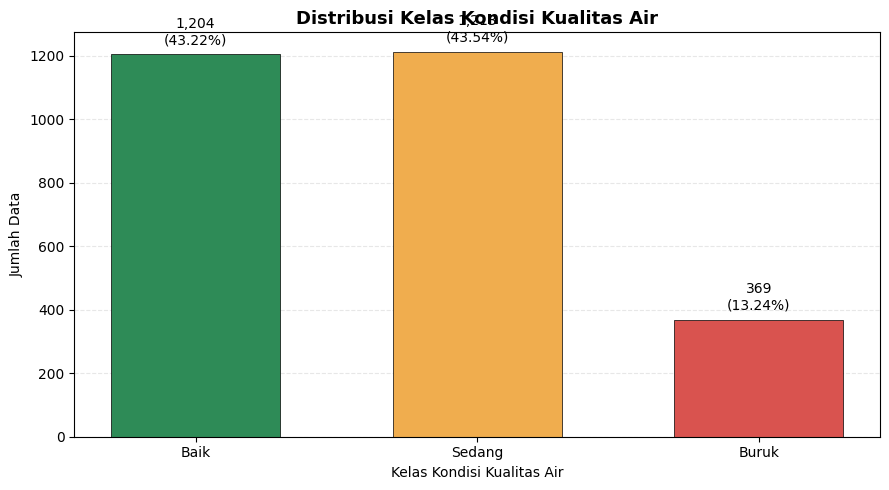

In [ ]:
# ============================================================
# 6.6 VISUALISASI DISTRIBUSI HASIL PELABELAN
# ============================================================

import matplotlib.pyplot as plt

# Mengambil data distribusi tanpa baris total
data_grafik = tabel_distribusi_label[
    tabel_distribusi_label["Kelas"] != "Total"
]

# Warna berbeda untuk setiap kelas
warna_kelas = {
    "Baik": "#2E8B57",
    "Sedang": "#F0AD4E",
    "Buruk": "#D9534F"
}

warna = [
    warna_kelas[kelas]
    for kelas in data_grafik["Kelas"]
]

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    data_grafik["Kelas"],
    data_grafik["Jumlah Data"],
    color=warna,
    width=0.6,
    edgecolor="black",
    linewidth=0.5
)

# Menampilkan jumlah dan persentase di atas batang
for bar, jumlah, persentase in zip(
    bars,
    data_grafik["Jumlah Data"],
    data_grafik["Persentase (%)"]
):
    ax.annotate(
        f"{jumlah:,}\n({persentase:.2f}%)",
        xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=10
    )

ax.set_title(
    "Distribusi Kelas Kondisi Kualitas Air",
    fontsize=13,
    fontweight="bold"
)
ax.set_xlabel("Kelas Kondisi Kualitas Air")
ax.set_ylabel("Jumlah Data")

ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [ ]:

# ============================================================
# 6.5 VALIDASI HASIL RULE-BASED LABELING
# ============================================================

# Memastikan semua nilai Ni berada pada rentang 0–4
assert df_model["N_i"].between(0, 4).all(), (
    "Terdapat nilai Ni di luar rentang 0–4."
)

# Memastikan label sesuai dengan nilai Ni
label_valid = (
    ((df_model["N_i"] >= 3) & (df_model["Label"] == "Baik")) |
    ((df_model["N_i"] == 2) & (df_model["Label"] == "Sedang")) |
    ((df_model["N_i"] <= 1) & (df_model["Label"] == "Buruk"))
)

assert label_valid.all(), (
    "Terdapat label yang tidak sesuai dengan aturan."
)

# Memastikan tidak ada label kosong
assert df_model["Label"].notna().all(), (
    "Terdapat label yang kosong."
)

print("Validasi berhasil.")
print("Seluruh label sesuai dengan aturan dalam proposal.")

print("\nJumlah data berlabel:", len(df_model))
print("\nDistribusi label:")
print(
    df_model["Label"]
    .value_counts()
    .reindex(["Baik", "Sedang", "Buruk"], fill_value=0)
)

print("\nContoh hasil akhir:")
display(
    df_model[
        kolom_parameter + kolom_indikator + ["N_i", "Label"]
    ].head(10)
)


Validasi berhasil.
Seluruh label sesuai dengan aturan dalam proposal.

Jumlah data berlabel: 2786

Distribusi label:
Label
Baik      1204
Sedang    1213
Buruk      369
Name: count, dtype: int64

Contoh hasil akhir:


,Suhu (°C),pH,TDS,Kekeruhan,I_Suhu,I_pH,I_TDS,I_Kekeruhan,N_i,Label
0,25.94,6.75,728.69,145.21,1,1,1,0,3,Baik
1,25.94,6.75,728.69,145.21,1,1,1,0,3,Baik
2,25.94,6.75,688.40,142.87,1,1,1,0,3,Baik
3,25.94,6.75,670.59,123.75,1,1,1,0,3,Baik
4,25.94,6.75,650.11,103.29,1,1,1,0,3,Baik
5,25.94,6.75,630.18,113.19,1,1,1,0,3,Baik
6,25.94,6.36,640.94,96.54,1,0,1,0,2,Sedang
7,25.94,6.36,626.76,100.17,1,0,1,0,2,Sedang
8,25.94,6.36,666.09,130.03,1,0,1,0,2,Sedang
9,25.94,6.35,615.78,113.89,1,0,1,0,2,Sedang


In [ ]:

# ============================================================
# 6.6 MENYIMPAN HASIL RULE-BASED LABELING
# ============================================================

nama_file = "Hasil_Rule_Based_Labeling.xlsx"

df_model.to_excel(nama_file, index=False)

print(f"Hasil labeling berhasil disimpan: {nama_file}")


Hasil labeling berhasil disimpan: Hasil_Rule_Based_Labeling.xlsx


# Menentukan Fitur (X) DAN Target (y)

In [ ]:

# Menentukan empat fitur kualitas air
fitur = [
    "Suhu (°C)",
    "pH",
    "TDS",
    "Kekeruhan"
]

# Memastikan kolom target tersedia
if "Label" not in df_model.columns:
    raise ValueError(
        "Kolom Label belum tersedia. "
        "Selesaikan tahap Rule-Based Labeling terlebih dahulu."
    )

# Memisahkan fitur dan target
X = df_model[fitur].copy()
y = df_model["Label"].copy()

print("Pemisahan fitur dan target berhasil.")


Pemisahan fitur dan target berhasil.


In [ ]:

# ============================================================
# 7.2 MEMERIKSA FITUR DAN TARGET
# ============================================================

# Memeriksa jumlah data dan fitur
print("Jumlah data:", len(X))
print("Jumlah fitur:", X.shape[1])
print("Nama fitur:", X.columns.tolist())
print("Jumlah target:", len(y))

# Memastikan jumlah baris sama
assert len(X) == len(y), (
    "Jumlah baris fitur dan target tidak sama."
)

# Memastikan tidak ada missing value
assert X.notna().all().all(), (
    "Masih terdapat missing value pada fitur X."
)

assert y.notna().all(), (
    "Masih terdapat missing value pada target y."
)

# Memeriksa kelas target
print("\nDistribusi kelas target:")
print(
    y.value_counts()
    .reindex(["Baik", "Sedang", "Buruk"], fill_value=0)
)

print("\nLima baris pertama fitur X:")
display(X.head())

print("\nLima baris pertama target y:")
display(y.head())

print("\nPemeriksaan fitur dan target selesai.")


Jumlah data: 2786
Jumlah fitur: 4
Nama fitur: ['Suhu (°C)', 'pH', 'TDS', 'Kekeruhan']
Jumlah target: 2786

Distribusi kelas target:
Label
Baik      1204
Sedang    1213
Buruk      369
Name: count, dtype: int64

Lima baris pertama fitur X:


,Suhu (°C),pH,TDS,Kekeruhan
0,25.94,6.75,728.69,145.21
1,25.94,6.75,728.69,145.21
2,25.94,6.75,688.40,142.87
3,25.94,6.75,670.59,123.75
4,25.94,6.75,650.11,103.29



Lima baris pertama target y:


,Label
0,Baik
1,Baik
2,Baik
3,Baik
4,Baik



Pemeriksaan fitur dan target selesai.


# Menentukan Skenario Pembagian Data

In [ ]:

from sklearn.model_selection import train_test_split

# Menentukan rasio data latih dan data uji
skenario_pembagian = {
    "70:30": 0.30,
    "80:20": 0.20,
    "90:10": 0.10
}

# Menetapkan random_state agar hasil pembagian konsisten
random_state = 42

print("Skenario pembagian data:")
for nama_skenario, proporsi_uji in skenario_pembagian.items():
    print(
        f"{nama_skenario} | "
        f"Data latih: {1 - proporsi_uji:.0%} | "
        f"Data uji: {proporsi_uji:.0%}"
    )


Skenario pembagian data:
70:30 | Data latih: 70% | Data uji: 30%
80:20 | Data latih: 80% | Data uji: 20%
90:10 | Data latih: 90% | Data uji: 10%


In [ ]:

hasil_pembagian = {}

for nama_skenario, proporsi_uji in skenario_pembagian.items():

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=proporsi_uji,
        random_state=random_state,
        stratify=y
    )

    hasil_pembagian[nama_skenario] = {
        "X_train": X_train,
        "X_test": X_test,
        "y_train": y_train,
        "y_test": y_test
    }

print("Pembagian data selesai untuk seluruh skenario.")


Pembagian data selesai untuk seluruh skenario.


In [ ]:

# ============================================================
# 8.3 MEMERIKSA HASIL PEMBAGIAN DATA
# ============================================================

ringkasan_pembagian = []

for nama_skenario, data in hasil_pembagian.items():

    X_train = data["X_train"]
    X_test = data["X_test"]
    y_train = data["y_train"]
    y_test = data["y_test"]

    ringkasan_pembagian.append({
        "Skenario": nama_skenario,
        "Jumlah Data Latih": len(X_train),
        "Jumlah Data Uji": len(X_test),
        "Total Data": len(X_train) + len(X_test),
        "Proporsi Latih Aktual (%)": round(
            len(X_train) / len(X) * 100, 2
        ),
        "Proporsi Uji Aktual (%)": round(
            len(X_test) / len(X) * 100, 2
        )
    })

    print(f"\nSkenario {nama_skenario}")
    print("Distribusi kelas data latih:")
    print(y_train.value_counts().reindex(
        ["Baik", "Sedang", "Buruk"], fill_value=0
    ))

    print("Distribusi kelas data uji:")
    print(y_test.value_counts().reindex(
        ["Baik", "Sedang", "Buruk"], fill_value=0
    ))

df_ringkasan_pembagian = pd.DataFrame(ringkasan_pembagian)

print("\nRingkasan seluruh skenario:")
display(df_ringkasan_pembagian)



Skenario 70:30
Distribusi kelas data latih:
Label
Baik      843
Sedang    849
Buruk     258
Name: count, dtype: int64
Distribusi kelas data uji:
Label
Baik      361
Sedang    364
Buruk     111
Name: count, dtype: int64

Skenario 80:20
Distribusi kelas data latih:
Label
Baik      963
Sedang    970
Buruk     295
Name: count, dtype: int64
Distribusi kelas data uji:
Label
Baik      241
Sedang    243
Buruk      74
Name: count, dtype: int64

Skenario 90:10
Distribusi kelas data latih:
Label
Baik      1083
Sedang    1092
Buruk      332
Name: count, dtype: int64
Distribusi kelas data uji:
Label
Baik      121
Sedang    121
Buruk      37
Name: count, dtype: int64

Ringkasan seluruh skenario:


,Skenario,Jumlah Data Latih,Jumlah Data Uji,Total Data,Proporsi Latih Aktual (%),Proporsi Uji Aktual (%)
0,70:30,1950,836,2786,69.99,30.01
1,80:20,2228,558,2786,79.97,20.03
2,90:10,2507,279,2786,89.99,10.01


# Standarisasi Data

In [ ]:

# 9.1 StandardScaler untuk setiap skenario pembagian data

from sklearn.preprocessing import StandardScaler

hasil_standardisasi = {}

for nama_skenario, data in hasil_pembagian.items():

    # Mengambil data latih dan data uji
    X_train = data["X_train"]
    X_test = data["X_test"]

    # Membuat scaler untuk skenario ini
    scaler = StandardScaler()

    # Fit hanya pada data latih, lalu transformasikan
    X_train_scaled = scaler.fit_transform(X_train)

    # Data uji hanya ditransformasikan
    X_test_scaled = scaler.transform(X_test)

    # Mengembalikan hasil ke DataFrame agar nama fitur tetap terlihat
    X_train_scaled = pd.DataFrame(
        X_train_scaled,
        columns=X_train.columns,
        index=X_train.index
    )

    X_test_scaled = pd.DataFrame(
        X_test_scaled,
        columns=X_test.columns,
        index=X_test.index
    )

    # Menyimpan hasil standardisasi
    hasil_standardisasi[nama_skenario] = {
        "X_train_scaled": X_train_scaled,
        "X_test_scaled": X_test_scaled,
        "y_train": data["y_train"].copy(),
        "y_test": data["y_test"].copy(),
        "scaler": scaler
    }

print("Standardisasi selesai untuk seluruh skenario.")


Standardisasi selesai untuk seluruh skenario.


In [ ]:

# ============================================================
# 9.2 MEMERIKSA HASIL STANDARDISASI
# ============================================================

for nama_skenario, data in hasil_standardisasi.items():

    X_train_scaled = data["X_train_scaled"]
    X_test_scaled = data["X_test_scaled"]

    print(f"\nSkenario {nama_skenario}")

    print("\nRata-rata fitur data latih setelah standardisasi:")
    print(X_train_scaled.mean().round(4))

    print("\nStandar deviasi fitur data latih:")
    print(X_train_scaled.std(ddof=0).round(4))

    print("\nContoh data latih terstandardisasi:")
    display(X_train_scaled.head())

    print("\nContoh data uji terstandardisasi:")
    display(X_test_scaled.head())



Skenario 70:30

Rata-rata fitur data latih setelah standardisasi:
Suhu (°C)    0.0
pH          -0.0
TDS          0.0
Kekeruhan   -0.0
dtype: float64

Standar deviasi fitur data latih:
Suhu (°C)    1.0
pH           1.0
TDS          1.0
Kekeruhan    1.0
dtype: float64

Contoh data latih terstandardisasi:


,Suhu (°C),pH,TDS,Kekeruhan
46,-0.040688,-0.583125,0.777560,-1.235399
57,-0.001636,-0.583125,0.550889,-1.583115
1467,-1.223398,-0.300916,-0.701413,0.909406
307,0.204780,-0.319730,0.847899,0.916596
1336,0.729189,-0.244474,-0.714787,0.839739



Contoh data uji terstandardisasi:


,Suhu (°C),pH,TDS,Kekeruhan
2621,-1.396341,0.112991,0.113298,0.688628
1905,-0.771514,-0.282102,-0.425556,0.803790
680,0.204780,-0.300916,0.024025,0.915852
1837,0.483721,-0.282102,-0.066856,0.868126
133,-0.420048,-0.470241,0.856803,-1.130774



Skenario 80:20

Rata-rata fitur data latih setelah standardisasi:
Suhu (°C)    0.0
pH           0.0
TDS         -0.0
Kekeruhan    0.0
dtype: float64

Standar deviasi fitur data latih:
Suhu (°C)    1.0
pH           1.0
TDS          1.0
Kekeruhan    1.0
dtype: float64

Contoh data latih terstandardisasi:


,Suhu (°C),pH,TDS,Kekeruhan
1497,0.239027,-0.095111,-0.746043,0.842215
1854,0.552285,-0.284044,-0.591753,0.908637
430,0.652976,-0.340724,0.468470,0.345161
365,-1.545430,-0.321831,1.568172,0.157871
1629,-1.304892,-0.302937,-0.331608,0.913822


... (2 outputs left out)


Skenario 90:10

Rata-rata fitur data latih setelah standardisasi:
Suhu (°C)    0.0
pH           0.0
TDS          0.0
Kekeruhan    0.0
dtype: float64

Standar deviasi fitur data latih:
Suhu (°C)    1.0
pH           1.0
TDS          1.0
Kekeruhan    1.0
dtype: float64

Contoh data latih terstandardisasi:


,Suhu (°C),pH,TDS,Kekeruhan
1561,0.453958,-0.203618,1.001281,0.155823
2330,1.217643,-0.260502,-0.611243,0.155823
2461,-1.045539,0.023919,-0.959054,-2.492393
2306,0.208687,-0.298425,-0.895822,-1.292578
943,0.247708,-0.469078,-0.765239,-1.936462



Contoh data uji terstandardisasi:


,Suhu (°C),pH,TDS,Kekeruhan
1930,0.559871,-0.241541,-0.664391,0.371642
26,-1.775778,-0.601807,-0.003628,-2.012713
2325,1.184197,-0.241541,-0.611243,0.155823
927,-1.324256,-0.412194,-0.848641,-2.224836
975,1.217643,-0.127773,-0.530695,-1.765113


In [ ]:
# Tabel 4.15 Hasil Pemeriksaan Standardisasi Data

ringkasan_standardisasi = []

for nama_skenario, data in hasil_standardisasi.items():

    X_train_scaled = data["X_train_scaled"]

    rata_rata = X_train_scaled.mean()
    standar_deviasi = X_train_scaled.std(ddof=0)

    for fitur in X_train_scaled.columns:
        ringkasan_standardisasi.append({
            "Skenario": nama_skenario,
            "Fitur": fitur,
            "Rata-rata": rata_rata[fitur],
            "Standar Deviasi": standar_deviasi[fitur]
        })

df_ringkasan_standardisasi = pd.DataFrame(ringkasan_standardisasi)

df_ringkasan_standardisasi["Rata-rata"] = (
    df_ringkasan_standardisasi["Rata-rata"].round(4)
)

df_ringkasan_standardisasi["Standar Deviasi"] = (
    df_ringkasan_standardisasi["Standar Deviasi"].round(4)
)

display(df_ringkasan_standardisasi)

,Skenario,Fitur,Rata-rata,Standar Deviasi
0,70:30,Suhu (°C),0.0,1.0
1,70:30,pH,-0.0,1.0
2,70:30,TDS,0.0,1.0
3,70:30,Kekeruhan,-0.0,1.0
4,80:20,Suhu (°C),0.0,1.0
5,80:20,pH,0.0,1.0
6,80:20,TDS,-0.0,1.0
7,80:20,Kekeruhan,0.0,1.0
8,90:10,Suhu (°C),0.0,1.0
9,90:10,pH,0.0,1.0


# Ketidak Seimbangan Kelas

In [ ]:
# 10.1 MEMERIKSA DISTRIBUSI KELAS DATA LATIH

for nama_skenario, data in hasil_standardisasi.items():

    y_train = data["y_train"]

    print(f"\nSkenario pembagian data {nama_skenario}")
    print("Distribusi kelas data latih:")

    distribusi = (
        y_train.value_counts()
        .reindex(["Baik", "Sedang", "Buruk"], fill_value=0)
    )

    display(distribusi)



Skenario pembagian data 70:30
Distribusi kelas data latih:


,count
Label,
Baik,843
Sedang,849
Buruk,258



Skenario pembagian data 80:20
Distribusi kelas data latih:


,count
Label,
Baik,963
Sedang,970
Buruk,295



Skenario pembagian data 90:10
Distribusi kelas data latih:


,count
Label,
Baik,1083
Sedang,1092
Buruk,332


In [ ]:

# ============================================================
# 10.2 MENYIAPKAN SKENARIO TANPA SMOTE DAN DENGAN SMOTE
# ============================================================

from imblearn.over_sampling import SMOTE

hasil_smote = {}

for nama_skenario, data in hasil_standardisasi.items():

    X_train_scaled = data["X_train_scaled"]
    X_test_scaled = data["X_test_scaled"]
    y_train = data["y_train"]
    y_test = data["y_test"]

    # --------------------------------------------
    # Skenario 1: Tanpa SMOTE
    # --------------------------------------------
    hasil_smote[(nama_skenario, "Tanpa SMOTE")] = {
        "X_train": X_train_scaled.copy(),
        "y_train": y_train.copy(),
        "X_test": X_test_scaled.copy(),
        "y_test": y_test.copy()
    }

    # --------------------------------------------
    # Skenario 2: Dengan SMOTE
    # --------------------------------------------
    jumlah_kelas = y_train.value_counts()

    # SMOTE standar membutuhkan minimal 6 sampel
    # pada setiap kelas agar k_neighbors=5 dapat digunakan.
    if jumlah_kelas.min() < 6:
        print(
            f"\nSkenario {nama_skenario}: SMOTE dilewati "
            "karena ada kelas dengan kurang dari 6 sampel."
        )
        continue

    smote = SMOTE(
        random_state=42,
        k_neighbors=5
    )

    X_train_smote, y_train_smote = smote.fit_resample(
        X_train_scaled,
        y_train
    )

    hasil_smote[(nama_skenario, "Dengan SMOTE")] = {
        "X_train": X_train_smote,
        "y_train": y_train_smote,
        "X_test": X_test_scaled.copy(),
        "y_test": y_test.copy()
    }

print("\nPersiapan skenario SMOTE selesai.")



Persiapan skenario SMOTE selesai.


In [ ]:

# ============================================================
# 10.3 MEMBANDINGKAN DISTRIBUSI KELAS
# ============================================================

for nama_skenario in skenario_pembagian:

    print(f"\n{'=' * 50}")
    print(f"SKENARIO PEMBAGIAN DATA {nama_skenario}")
    print(f"{'=' * 50}")

    # Distribusi sebelum SMOTE
    print("\nSebelum SMOTE:")
    display(
        hasil_standardisasi[nama_skenario]["y_train"]
        .value_counts()
        .reindex(["Baik", "Sedang", "Buruk"], fill_value=0)
    )

    # Distribusi setelah SMOTE, jika berhasil dibuat
    kunci_smote = (nama_skenario, "Dengan SMOTE")

    if kunci_smote in hasil_smote:
        print("\nSesudah SMOTE:")
        display(
            hasil_smote[kunci_smote]["y_train"]
            .value_counts()
            .reindex(["Baik", "Sedang", "Buruk"], fill_value=0)
        )
    else:
        print("\nSkenario SMOTE tidak tersedia.")



SKENARIO PEMBAGIAN DATA 70:30

Sebelum SMOTE:


,count
Label,
Baik,843
Sedang,849
Buruk,258



Sesudah SMOTE:


,count
Label,
Baik,849
Sedang,849
Buruk,849



SKENARIO PEMBAGIAN DATA 80:20

Sebelum SMOTE:


,count
Label,
Baik,963
Sedang,970
Buruk,295


... (2 outputs left out)


SKENARIO PEMBAGIAN DATA 90:10

Sebelum SMOTE:


,count
Label,
Baik,1083
Sedang,1092
Buruk,332



Sesudah SMOTE:


,count
Label,
Baik,1092
Sedang,1092
Buruk,1092


# Pemodelan dan Pengujian KNN

In [ ]:

# ============================================================
# 11. PEMODELAN DAN PENGUJIAN KNN
# 11.1 MENYIAPKAN MODEL DAN METRIK
# ============================================================

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Nilai K yang akan diuji
daftar_k = [3, 5, 7, 9, 11]

# Menampung seluruh hasil eksperimen
hasil_eksperimen = []

print("Nilai K yang diuji:", daftar_k)
print("Jumlah skenario pembagian data:", len(skenario_pembagian))
print("Jumlah konfigurasi SMOTE: 2")
print("Maksimal jumlah eksperimen:", 3 * 2 * len(daftar_k))


Nilai K yang diuji: [3, 5, 7, 9, 11]
Jumlah skenario pembagian data: 3
Jumlah konfigurasi SMOTE: 2
Maksimal jumlah eksperimen: 30


In [ ]:

# ============================================================
# 11.2 MENJALANKAN EKSPERIMEN KNN
# ============================================================

for (nama_skenario, metode_sampling), data in hasil_smote.items():

    X_train = data["X_train"]
    y_train = data["y_train"]
    X_test = data["X_test"]
    y_test = data["y_test"]

    for k in daftar_k:

        # Memastikan jumlah data latih mencukupi
        if len(X_train) < k:
            print(
                f"Dilewati: rasio {nama_skenario}, "
                f"{metode_sampling}, K={k}; "
                "data latih tidak mencukupi."
            )
            continue

        # Membuat dan melatih model KNN
        model = KNeighborsClassifier(
            n_neighbors=k,
            metric="euclidean"
        )

        model.fit(X_train, y_train)

        # Prediksi pada data uji
        y_pred = model.predict(X_test)

        # Menghitung metrik evaluasi
        hasil_eksperimen.append({
            "Skenario": nama_skenario,
            "Metode Sampling": metode_sampling,
            "K": k,
            "Jumlah Data Latih": len(X_train),
            "Jumlah Data Uji": len(X_test),
            "Accuracy": accuracy_score(y_test, y_pred),
            "Precision Macro": precision_score(
                y_test, y_pred,
                average="macro",
                zero_division=0
            ),
            "Recall Macro": recall_score(
                y_test, y_pred,
                average="macro",
                zero_division=0
            ),
            "F1-Score Macro": f1_score(
                y_test, y_pred,
                average="macro",
                zero_division=0
            )
        })

print("Seluruh eksperimen yang tersedia telah dijalankan.")
print("Jumlah eksperimen yang berhasil:", len(hasil_eksperimen))


Seluruh eksperimen yang tersedia telah dijalankan.
Jumlah eksperimen yang berhasil: 30


In [ ]:

# ============================================================
# 11.3 MENAMPILKAN HASIL PENGUJIAN KNN
# ============================================================

df_hasil_eksperimen = pd.DataFrame(hasil_eksperimen)

if df_hasil_eksperimen.empty:
    raise ValueError(
        "Belum ada hasil eksperimen. "
        "Periksa kembali hasil pembagian data dan SMOTE."
    )

kolom_metrik = [
    "Accuracy",
    "Precision Macro",
    "Recall Macro",
    "F1-Score Macro"
]

# Menampilkan nilai metrik dalam bentuk persentase
df_tampilan = df_hasil_eksperimen.copy()
df_tampilan[kolom_metrik] = (
    df_tampilan[kolom_metrik] * 100
).round(2)

display(
    df_tampilan.sort_values(
        ["Skenario", "Metode Sampling", "K"]
    ).reset_index(drop=True)
)


,Skenario,Metode Sampling,K,Jumlah Data Latih,Jumlah Data Uji,Accuracy,Precision Macro,Recall Macro,F1-Score Macro
0,70:30,Dengan SMOTE,3,2547,836,91.87,90.24,91.25,90.72
1,70:30,Dengan SMOTE,5,2547,836,91.75,90.17,92.20,91.10
2,70:30,Dengan SMOTE,7,2547,836,91.75,89.33,92.00,90.51
3,70:30,Dengan SMOTE,9,2547,836,91.39,88.48,91.72,89.83
4,70:30,Dengan SMOTE,11,2547,836,89.95,86.88,90.42,88.31
5,70:30,Tanpa SMOTE,3,1950,836,92.22,91.82,90.69,91.23
6,70:30,Tanpa SMOTE,5,1950,836,91.15,90.96,89.45,90.16
7,70:30,Tanpa SMOTE,7,1950,836,91.87,91.27,89.79,90.49
8,70:30,Tanpa SMOTE,9,1950,836,92.11,92.08,89.98,90.94
9,70:30,Tanpa SMOTE,11,1950,836,90.79,89.80,88.76,89.25


# Perbandingan Hasil Skenario

# Validasi silang untuk pemilihan konfigurasi KNN

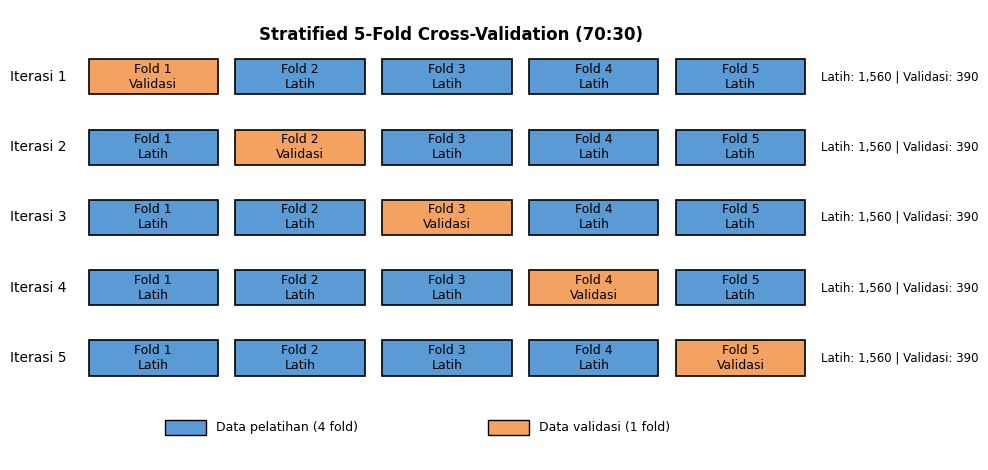

In [ ]:
# ============================================================
# VISUALISASI PEMBAGIAN STRATIFIED 5-FOLD CROSS-VALIDATION
# ============================================================

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# Visualisasi menggunakan data training dari skenario pertama.
# Pembagian fold mengikuti StratifiedKFold yang digunakan pada proses CV.
nama_skenario_visual = list(hasil_pembagian.keys())[0]
data_visual = hasil_pembagian[nama_skenario_visual]
X_visual = data_visual["X_train"]
y_visual = data_visual["y_train"]

cv_visual = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.set_xlim(0, 5)
ax.set_ylim(-0.7, 5.7)
ax.axis("off")

# Judul
ax.text(
    2.5, 5.35,
    f"Stratified 5-Fold Cross-Validation ({nama_skenario_visual})",
    ha="center", va="center", fontsize=12, fontname="Helvetica",
    fontweight="bold"
)

# Lima baris menunjukkan lima iterasi validasi.
# Biru = data pelatihan; oranye = data validasi.
for iterasi, (idx_train, idx_validasi) in enumerate(
    cv_visual.split(X_visual, y_visual), start=1
):
    y_pos = 4.5 - (iterasi - 1)

    ax.text(
        -0.12, y_pos + 0.25, f"Iterasi {iterasi}",
        ha="right", va="center", fontsize=10, fontname="Helvetica"
    )

    for fold in range(5):
        is_validation = (fold == iterasi - 1)
        facecolor = "#F4A261" if is_validation else "#5B9BD5"
        label = "Validasi" if is_validation else "Latih"

        rect = Rectangle(
            (fold + 0.03, y_pos), 0.88, 0.5,
            facecolor=facecolor, edgecolor="black", linewidth=1.2
        )
        ax.add_patch(rect)
        ax.text(
            fold + 0.47, y_pos + 0.25,
            f"Fold {fold + 1}\n{label}",
            ha="center", va="center", fontsize=9,
            fontname="Helvetica",
            color="black"
        )

    # Jumlah sampel aktual pada iterasi tersebut.
    ax.text(
        5.02, y_pos + 0.25,
        f"Latih: {len(idx_train):,} | Validasi: {len(idx_validasi):,}",
        ha="left", va="center", fontsize=8.5, fontname="Helvetica"
    )

# Keterangan
ax.add_patch(Rectangle(
    (0.55, -0.35), 0.28, 0.22,
    facecolor="#5B9BD5", edgecolor="black", linewidth=1
))
ax.text(
    0.9, -0.24, "Data pelatihan (4 fold)",
    va="center", fontsize=9, fontname="Helvetica"
)
ax.add_patch(Rectangle(
    (2.75, -0.35), 0.28, 0.22,
    facecolor="#F4A261", edgecolor="black", linewidth=1
))
ax.text(
    3.1, -0.24, "Data validasi (1 fold)",
    va="center", fontsize=9, fontname="Helvetica"
)

plt.tight_layout()
plt.show()


In [ ]:
# ============================================================
# 11.4 VALIDASI SILANG UNTUK PEMILIHAN KONFIGURASI KNN
# ============================================================

import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

# Validasi silang dilakukan hanya pada data latih dari setiap rasio.
# Data uji tidak digunakan untuk memilih nilai K atau metode sampling.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
hasil_validasi = []

for nama_skenario, data_split in hasil_pembagian.items():
    X_train_cv = data_split["X_train"]
    y_train_cv = data_split["y_train"]

    for metode_sampling in ["Tanpa SMOTE", "Dengan SMOTE"]:
        for k in daftar_k:
            langkah = [("scaler", StandardScaler())]

            if metode_sampling == "Dengan SMOTE":
                # k_neighbors=5; SMOTE hanya diterapkan pada fold pelatihan
                langkah.append(("smote", SMOTE(random_state=42, k_neighbors=5)))

            langkah.append(("knn", KNeighborsClassifier(
                n_neighbors=k,
                metric="euclidean"
            )))
            pipeline = ImbPipeline(steps=langkah)

            try:
                skor = cross_validate(
                    pipeline,
                    X_train_cv,
                    y_train_cv,
                    cv=cv,
                    scoring={
                        "accuracy": "accuracy",
                        "precision_macro": "precision_macro",
                        "recall_macro": "recall_macro",
                        "f1_macro": "f1_macro"
                    },
                    return_train_score=False,
                    error_score="raise"
                )

                hasil_validasi.append({
                    "Skenario": nama_skenario,
                    "Metode Sampling": metode_sampling,
                    "K": k,
                    "CV Accuracy Mean": skor["test_accuracy"].mean(),
                    "CV Precision Macro Mean": skor["test_precision_macro"].mean(),
                    "CV Recall Macro Mean": skor["test_recall_macro"].mean(),
                    "CV F1-Score Macro Mean": skor["test_f1_macro"].mean(),
                    "CV F1-Score Macro SD": skor["test_f1_macro"].std(ddof=1)
                })
            except ValueError as e:
                print(f"Konfigurasi dilewati: {nama_skenario}, {metode_sampling}, K={k}. Alasan: {e}")


df_hasil_validasi = pd.DataFrame(hasil_validasi)
if df_hasil_validasi.empty:
    raise ValueError("Tidak ada hasil cross-validation. Periksa distribusi kelas pada data latih.")

print("Hasil validasi silang (rata-rata dari 5 fold):")
display(df_hasil_validasi.sort_values(
    ["Skenario", "Metode Sampling", "K"]
).reset_index(drop=True))

# Gabungkan skor validasi dengan hasil pengujian lama untuk pelaporan.
# Pemilihan konfigurasi berikutnya didasarkan pada skor CV, bukan skor data uji.
df_hasil_model = df_hasil_eksperimen.merge(
    df_hasil_validasi,
    on=["Skenario", "Metode Sampling", "K"],
    how="inner"
)
print("Jumlah konfigurasi yang memiliki hasil uji dan validasi:", len(df_hasil_model))


Hasil validasi silang (rata-rata dari 5 fold):


,Skenario,Metode Sampling,K,CV Accuracy Mean,CV Precision Macro Mean,CV Recall Macro Mean,CV F1-Score Macro Mean,CV F1-Score Macro SD
0,70:30,Dengan SMOTE,3,0.912308,0.892631,0.913891,0.901392,0.012937
1,70:30,Dengan SMOTE,5,0.904103,0.878054,0.910300,0.890562,0.019325
2,70:30,Dengan SMOTE,7,0.890769,0.861985,0.898310,0.875215,0.011062
3,70:30,Dengan SMOTE,9,0.889744,0.861925,0.902916,0.876362,0.016891
4,70:30,Dengan SMOTE,11,0.889744,0.861039,0.903810,0.875680,0.020662
5,70:30,Tanpa SMOTE,3,0.916410,0.908464,0.908015,0.907681,0.011940
6,70:30,Tanpa SMOTE,5,0.902051,0.885214,0.886221,0.884622,0.011889
7,70:30,Tanpa SMOTE,7,0.892308,0.876970,0.872559,0.874001,0.011662
8,70:30,Tanpa SMOTE,9,0.888718,0.873501,0.872534,0.872300,0.015917
9,70:30,Tanpa SMOTE,11,0.885641,0.870015,0.867470,0.867727,0.011494


Jumlah konfigurasi yang memiliki hasil uji dan validasi: 30


In [ ]:

# 12.1 MENYUSUN TABEL PERBANDINGAN

# Memastikan hasil eksperimen tersedia
if "df_hasil_eksperimen" not in globals():
    raise ValueError(
        "Hasil eksperimen belum tersedia. "
        "Jalankan tahap Nomor 11 terlebih dahulu."
    )

# Menentukan kolom yang ditampilkan
kolom_perbandingan = [
    "Skenario",
    "Metode Sampling",
    "K",
    "Accuracy",
    "Precision Macro",
    "Recall Macro",
    "F1-Score Macro"
]

df_perbandingan = df_hasil_eksperimen[
    kolom_perbandingan
].copy()

# Mengubah nilai metrik menjadi persentase untuk tampilan
kolom_metrik = [
    "Accuracy",
    "Precision Macro",
    "Recall Macro",
    "F1-Score Macro"
]

df_perbandingan[kolom_metrik] = (
    df_perbandingan[kolom_metrik] * 100
).round(2)

# Mengurutkan tabel berdasarkan skenario, sampling, dan K
urutan_rasio = ["70:30", "80:20", "90:10"]
urutan_sampling = ["Tanpa SMOTE", "Dengan SMOTE"]

df_perbandingan["Skenario"] = pd.Categorical(
    df_perbandingan["Skenario"],
    categories=urutan_rasio,
    ordered=True
)

df_perbandingan["Metode Sampling"] = pd.Categorical(
    df_perbandingan["Metode Sampling"],
    categories=urutan_sampling,
    ordered=True
)

df_perbandingan = df_perbandingan.sort_values(
    ["Skenario", "Metode Sampling", "K"]
).reset_index(drop=True)

display(df_perbandingan)


,Skenario,Metode Sampling,K,Accuracy,Precision Macro,Recall Macro,F1-Score Macro
0,70:30,Tanpa SMOTE,3,92.22,91.82,90.69,91.23
1,70:30,Tanpa SMOTE,5,91.15,90.96,89.45,90.16
2,70:30,Tanpa SMOTE,7,91.87,91.27,89.79,90.49
3,70:30,Tanpa SMOTE,9,92.11,92.08,89.98,90.94
4,70:30,Tanpa SMOTE,11,90.79,89.80,88.76,89.25
5,70:30,Dengan SMOTE,3,91.87,90.24,91.25,90.72
6,70:30,Dengan SMOTE,5,91.75,90.17,92.20,91.10
7,70:30,Dengan SMOTE,7,91.75,89.33,92.00,90.51
8,70:30,Dengan SMOTE,9,91.39,88.48,91.72,89.83
9,70:30,Dengan SMOTE,11,89.95,86.88,90.42,88.31


In [ ]:

# ============================================================
# 12.2 RINGKASAN RATA-RATA HASIL SETIAP SKENARIO
# ============================================================

df_ringkasan_skenario = (
    df_hasil_eksperimen
    .groupby(
        ["Skenario", "Metode Sampling"],
        observed=True
    )[kolom_metrik]
    .mean()
    .reset_index()
)

# Menampilkan metrik dalam persentase
df_ringkasan_tampilan = df_ringkasan_skenario.copy()

df_ringkasan_tampilan[kolom_metrik] = (
    df_ringkasan_tampilan[kolom_metrik] * 100
).round(2)

display(df_ringkasan_tampilan)


,Skenario,Metode Sampling,Accuracy,Precision Macro,Recall Macro,F1-Score Macro
0,70:30,Dengan SMOTE,91.34,89.02,91.52,90.09
1,70:30,Tanpa SMOTE,91.63,91.19,89.73,90.42
2,80:20,Dengan SMOTE,93.26,91.80,93.51,92.56
3,80:20,Tanpa SMOTE,92.26,92.66,89.49,90.88
4,90:10,Dengan SMOTE,92.11,89.71,92.31,90.80
5,90:10,Tanpa SMOTE,91.33,90.86,87.95,89.23


In [ ]:
# 12.3 PERINGKAT DESKRIPTIF BERDASARKAN HASIL UJI (BUKAN UNTUK PEMILIHAN MODEL)

df_peringkat_awal = (
    df_hasil_eksperimen
    .sort_values(
        by="F1-Score Macro",
        ascending=False
    )
    .reset_index(drop=True)
)

df_peringkat_tampilan = df_peringkat_awal.copy()

df_peringkat_tampilan[kolom_metrik] = (
    df_peringkat_tampilan[kolom_metrik] * 100
).round(2)

display(
    df_peringkat_tampilan[
        [
            "Skenario",
            "Metode Sampling",
            "K",
            "Accuracy",
            "Precision Macro",
            "Recall Macro",
            "F1-Score Macro"
        ]
    ]
)


,Skenario,Metode Sampling,K,Accuracy,Precision Macro,Recall Macro,F1-Score Macro
0,80:20,Dengan SMOTE,3,93.55,93.48,93.17,93.32
1,80:20,Dengan SMOTE,5,93.37,92.53,93.34,92.92
2,80:20,Dengan SMOTE,7,93.55,91.82,94.11,92.86
3,80:20,Dengan SMOTE,9,93.19,90.94,93.83,92.21
4,80:20,Tanpa SMOTE,5,92.47,93.59,90.15,91.66
5,80:20,Dengan SMOTE,11,92.65,90.26,93.11,91.50
6,90:10,Dengan SMOTE,7,92.83,90.04,93.24,91.40
7,70:30,Tanpa SMOTE,3,92.22,91.82,90.69,91.23
8,80:20,Tanpa SMOTE,3,92.29,92.71,90.01,91.23
9,90:10,Dengan SMOTE,9,92.47,89.76,92.96,91.13


# Menentukan peringkat konfigurasi KNN terbaik

In [ ]:
# Peringkat konfigurasi ditentukan dari rata-rata F1-Score Macro hasil cross-validation.
# Metrik data uji tidak digunakan untuk memilih konfigurasi terbaik.
df_peringkat_knn = df_hasil_model.copy()

df_peringkat_knn = df_peringkat_knn.sort_values(
    by=["CV F1-Score Macro Mean", "CV Accuracy Mean"],
    ascending=[False, False]
).reset_index(drop=True)

df_peringkat_knn.insert(0, "Peringkat", range(1, len(df_peringkat_knn) + 1))

df_tampilan_peringkat = df_peringkat_knn.copy()
kolom_metrik = [
    "Accuracy", "Precision Macro", "Recall Macro", "F1-Score Macro",
    "CV Accuracy Mean", "CV Precision Macro Mean", "CV Recall Macro Mean",
    "CV F1-Score Macro Mean", "CV F1-Score Macro SD"
]
df_tampilan_peringkat[kolom_metrik] = (df_tampilan_peringkat[kolom_metrik] * 100).round(2)

display(df_tampilan_peringkat[[
    "Peringkat", "Skenario", "Metode Sampling", "K",
    "CV Accuracy Mean", "CV Precision Macro Mean", "CV Recall Macro Mean",
    "CV F1-Score Macro Mean", "CV F1-Score Macro SD",
    "Accuracy", "Precision Macro", "Recall Macro", "F1-Score Macro"
]])

,Peringkat,Skenario,Metode Sampling,K,CV Accuracy Mean,CV Precision Macro Mean,CV Recall Macro Mean,CV F1-Score Macro Mean,CV F1-Score Macro SD,Accuracy,Precision Macro,Recall Macro,F1-Score Macro
0,1,80:20,Tanpa SMOTE,3,92.14,91.94,91.22,91.54,1.43,92.29,92.71,90.01,91.23
1,2,90:10,Tanpa SMOTE,3,92.14,91.58,91.24,91.36,1.77,92.11,91.83,89.56,90.60
2,3,90:10,Dengan SMOTE,3,91.90,89.95,92.25,90.96,1.97,92.11,90.81,90.81,90.81
3,4,80:20,Dengan SMOTE,3,91.74,89.74,92.25,90.82,1.00,93.55,93.48,93.17,93.32
4,5,70:30,Tanpa SMOTE,3,91.64,90.85,90.80,90.77,1.19,92.22,91.82,90.69,91.23
5,6,90:10,Tanpa SMOTE,5,91.58,90.52,90.75,90.58,1.65,89.96,90.81,86.66,88.41
6,7,90:10,Dengan SMOTE,5,91.54,89.18,92.32,90.49,1.41,91.40,89.65,92.14,90.76
7,8,70:30,Dengan SMOTE,3,91.23,89.26,91.39,90.14,1.29,91.87,90.24,91.25,90.72
8,9,80:20,Tanpa SMOTE,5,90.75,89.97,90.00,89.94,1.51,92.47,93.59,90.15,91.66
9,10,80:20,Dengan SMOTE,5,90.48,88.15,91.44,89.46,1.33,93.37,92.53,93.34,92.92


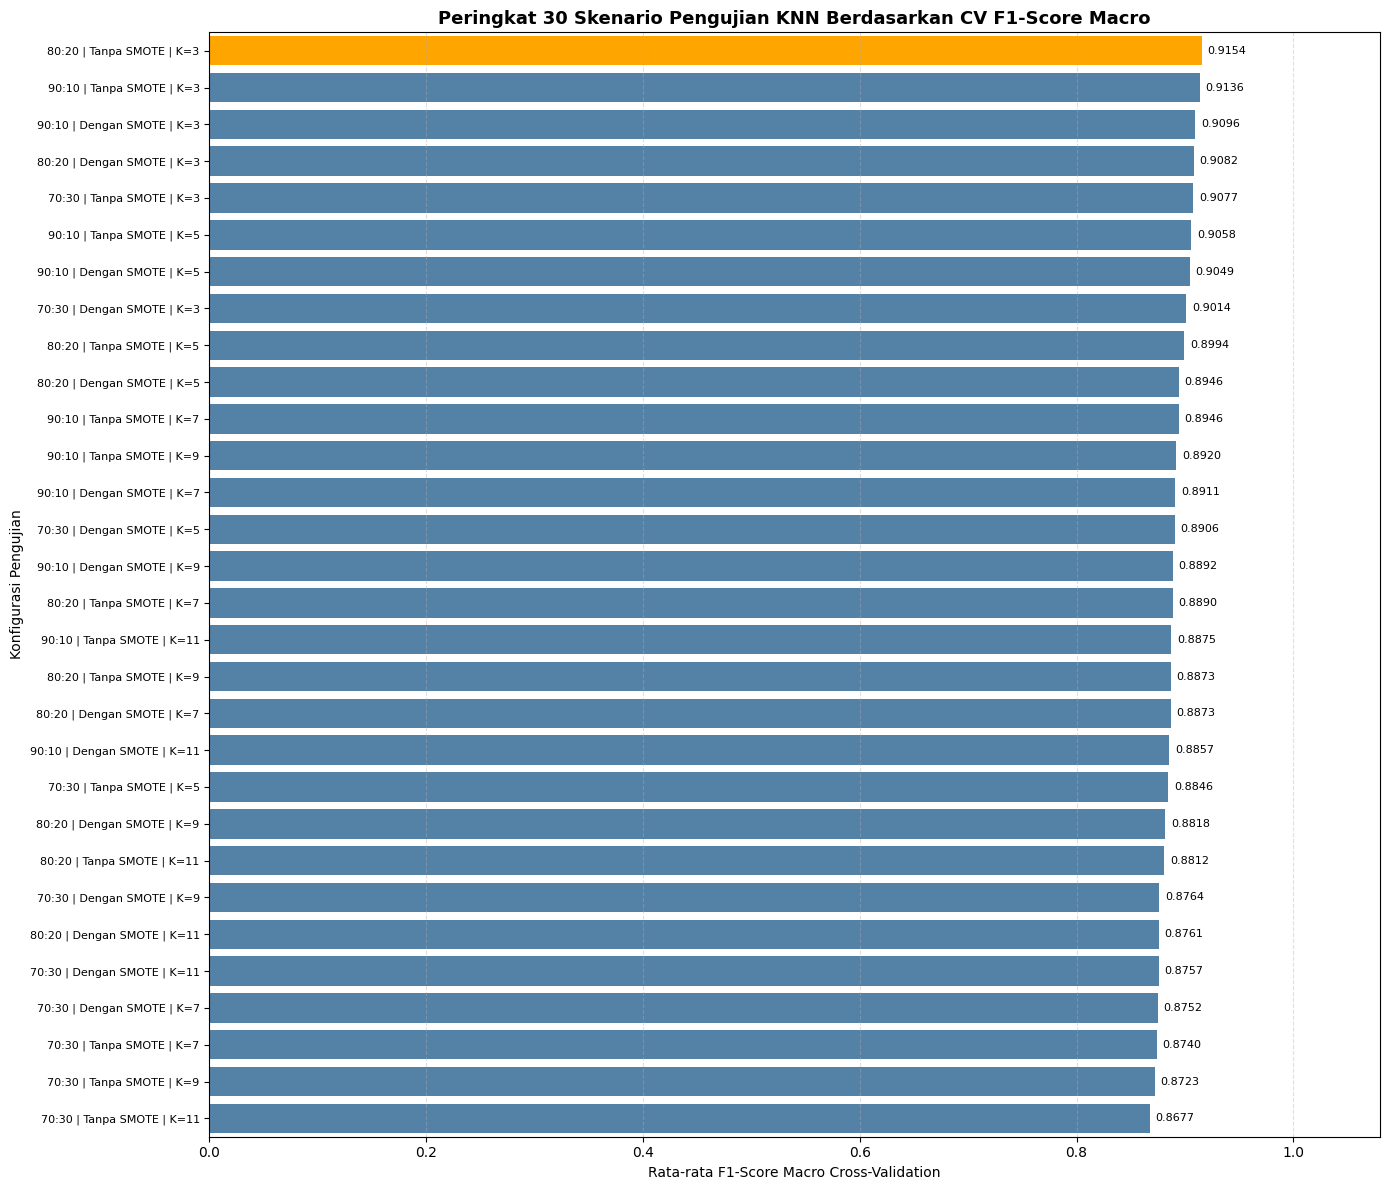

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Mengurutkan 30 konfigurasi berdasarkan peringkat
df_plot = df_peringkat_knn.sort_values(
    by="Peringkat",
    ascending=True
).copy()

# Membuat label konfigurasi
df_plot["Konfigurasi"] = (
    df_plot["Skenario"].astype(str)
    + " | "
    + df_plot["Metode Sampling"].astype(str)
    + " | K="
    + df_plot["K"].astype(str)
)

# Membuat diagram batang horizontal
plt.figure(figsize=(14, 12))

ax = sns.barplot(
    data=df_plot,
    x="CV F1-Score Macro Mean",
    y="Konfigurasi",
    color="steelblue"
)

# Menambahkan nilai F1-Score
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.4f",
        padding=4,
        fontsize=8
    )

# Menandai konfigurasi terbaik
ax.patches[0].set_facecolor("orange")

plt.title(
    "Peringkat 30 Skenario Pengujian KNN Berdasarkan CV F1-Score Macro",
    fontsize=13,
    fontweight="bold"
)
plt.xlabel("Rata-rata F1-Score Macro Cross-Validation")
plt.ylabel("Konfigurasi Pengujian")
plt.xlim(0, 1.08)
plt.yticks(fontsize=8)
plt.grid(axis="x", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

# Menyiapkan Model KNN Terbaik

In [ ]:
# Nomor 14.1 - Mengambil konfigurasi KNN terbaik

# Ambil konfigurasi dengan peringkat pertama
model_terbaik = df_peringkat_knn.iloc[0]

skenario_terbaik = model_terbaik["Skenario"]
sampling_terbaik = model_terbaik["Metode Sampling"]
k_terbaik = int(model_terbaik["K"])  # Perbaikan: menggunakan K huruf besar

# Ambil data sesuai konfigurasi terpilih
data_terbaik = hasil_smote[
    (skenario_terbaik, sampling_terbaik)
]

X_train_terbaik = data_terbaik["X_train"]
y_train_terbaik = data_terbaik["y_train"]
X_test_terbaik = data_terbaik["X_test"]
y_test_terbaik = data_terbaik["y_test"]

print("Konfigurasi KNN Terbaik")
print("Skenario pembagian  :", skenario_terbaik)
print("Metode sampling     :", sampling_terbaik)
print("Nilai K             :", k_terbaik)
print("Jumlah data training:", len(X_train_terbaik))
print("Jumlah data testing :", len(X_test_terbaik))

Konfigurasi KNN Terbaik
Skenario pembagian  : 80:20
Metode sampling     : Tanpa SMOTE
Nilai K             : 3
Jumlah data training: 2228
Jumlah data testing : 558


In [ ]:
# Nomor 14.2 - Melatih model KNN terbaik

from sklearn.neighbors import KNeighborsClassifier

# Latih model menggunakan data training terbaik
model_knn_terbaik = KNeighborsClassifier(
    n_neighbors=k_terbaik,
    metric="euclidean"
)

model_knn_terbaik.fit(
    X_train_terbaik,
    y_train_terbaik
)

print("Model KNN terbaik berhasil dilatih.")

Reference Accuracy (A_ref): 0.9229
Reference Accuracy        : 92.29%


In [ ]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

# Prediksi menggunakan model KNN terbaik
y_pred = model_knn_terbaik.predict(X_test_terbaik)

# Urutan kelas
labels = ['Baik', 'Sedang', 'Buruk']

# 1. Informasi pengujian
print("HASIL EVALUASI MODEL KNN")
print("=" * 50)
print(f"Jumlah data testing : {len(y_test_terbaik)}")
print(f"Jumlah kelas        : {len(labels)}")
print(f"Konfigurasi model   : KNN (K=3)")
print(f"Rasio pembagian     : 80:20")
print(f"Penggunaan SMOTE    : Tanpa SMOTE")

# 2. Confusion Matrix
cm = confusion_matrix(
    y_test_terbaik,
    y_pred,
    labels=labels
)

print("\nCONFUSION MATRIX")
print("=" * 50)

cm_df = pd.DataFrame(
    cm,
    index=[f"Aktual {label}" for label in labels],
    columns=[f"Prediksi {label}" for label in labels]
)

print(cm_df)

# 3. Classification Report
print("\nCLASSIFICATION REPORT")
print("=" * 50)

print(classification_report(
    y_test_terbaik,
    y_pred,
    labels=labels,
    target_names=labels,
    digits=4
))

# 4. Metrik Evaluasi
accuracy = accuracy_score(y_test_terbaik, y_pred)

precision = precision_score(
    y_test_terbaik,
    y_pred,
    labels=labels,
    average='macro',
    zero_division=0
)

recall = recall_score(
    y_test_terbaik,
    y_pred,
    labels=labels,
    average='macro',
    zero_division=0
)

f1 = f1_score(
    y_test_terbaik,
    y_pred,
    labels=labels,
    average='macro',
    zero_division=0
)

print("\nMETRIK EVALUASI MODEL")
print("=" * 50)
print(f"Accuracy  : {accuracy * 100:.2f}%")
print(f"Precision : {precision * 100:.2f}%")
print(f"Recall    : {recall * 100:.2f}%")
print(f"F1-Score  : {f1 * 100:.2f}%")

HASIL EVALUASI MODEL KNN
Jumlah data testing : 558
Jumlah kelas        : 3
Konfigurasi model   : KNN (K=3)
Rasio pembagian     : 80:20
Penggunaan SMOTE    : Tanpa SMOTE

CONFUSION MATRIX
               Prediksi Baik  Prediksi Sedang  Prediksi Buruk
Aktual Baik              227               14               0
Aktual Sedang             12              227               4
Aktual Buruk               2               11              61

CLASSIFICATION REPORT
              precision    recall  f1-score   support

        Baik     0.9419    0.9419    0.9419       241
      Sedang     0.9008    0.9342    0.9172       243
       Buruk     0.9385    0.8243    0.8777        74

    accuracy                         0.9229       558
   macro avg     0.9271    0.9001    0.9123       558
weighted avg     0.9235    0.9229    0.9226       558


METRIK EVALUASI MODEL
Accuracy  : 92.29%
Precision : 92.71%
Recall    : 90.01%
F1-Score  : 91.23%


# Confusion Matrix

In [ ]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    accuracy_score
)
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier

# Mengambil data training dan testing skenario 80:20
data_terbaik = hasil_standardisasi["80:20"]

X_train = data_terbaik["X_train_scaled"]
X_test = data_terbaik["X_test_scaled"]
y_train = data_terbaik["y_train"]
y_test = data_terbaik["y_test"]

# Melatih model KNN terbaik: tanpa SMOTE, K=3
model_knn_terbaik = KNeighborsClassifier(
    n_neighbors=3,
    metric="euclidean"
)

model_knn_terbaik.fit(X_train, y_train)

# Prediksi data uji
y_pred_terbaik = model_knn_terbaik.predict(X_test)

# Confusion Matrix
label_kelas = ["Baik", "Sedang", "Buruk"]

cm = confusion_matrix(
    y_test,
    y_pred_terbaik,
    labels=label_kelas
)

df_confusion_matrix = pd.DataFrame(
    cm,
    index=[f"Aktual {kelas}" for kelas in label_kelas],
    columns=[f"Prediksi {kelas}" for kelas in label_kelas]
)

print("Confusion Matrix:")
display(df_confusion_matrix)

# Classification Report
report = classification_report(
    y_test,
    y_pred_terbaik,
    labels=label_kelas,
    target_names=label_kelas,
    output_dict=True,
    zero_division=0
)

df_classification_report = pd.DataFrame(report).T

print("Classification Report:")
display(df_classification_report.round(4))

# Grafik Confusion Matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_kelas
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix KNN Terbaik (80:20, Tanpa SMOTE, K=3)")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.tight_layout()
plt.show()

# Akurasi pengujian
print("Accuracy:", round(accuracy_score(y_test, y_pred_terbaik), 4))

In [ ]:
# Nomor 14.4 - Classification Report

from sklearn.metrics import classification_report

laporan_klasifikasi = classification_report(
    y_test_terbaik,
    y_pred_terbaik,
    labels=urutan_kelas,
    target_names=urutan_kelas,
    zero_division=0,
    output_dict=True
)

df_classification_report = pd.DataFrame(
    laporan_klasifikasi
).transpose()

display(df_classification_report.round(4))